# 📘 CARACTERIZACIÓN FRACCIONARIA DE CUERDAS DE GUITARRA
## Fase 1: El Fantasma Físico

### Sección 0: Configuración del Entorno y Carga de Datos

**Objetivo:** Preparar el entorno computacional y cargar las señales acústicas sin alteración.

**Fundamento Teórico:**

Antes de aplicar cualquier operador fraccionario (Caputo, Hilbert), debemos garantizar que la señal entra íntegra al sistema. Esto es crítico porque:

1. **Preservación de la Memoria:** Cualquier pre-filtrado o compresión alteraría la "cola de memoria" que queremos caracterizar.
2. **Precisión Numérica:** Trabajaremos con señales de 24-bit para capturar el decaimiento completo hasta el piso de ruido.
3. **Tasa de Muestreo:** $f_s \geq 44.1 \text{ kHz}$ para satisfacer Nyquist y capturar armónicos hasta ~20 kHz.

**Referencia Tesis:** Sección 7.1 (Fase 1: Pre-procesamiento)

**Nota:** Este notebook sigue la metodología rigurosa establecida en el plan de trabajo de grado.

---

### Contexto Histórico-Matemático:

- **NumPy (2005):** Implementación eficiente de álgebra lineal, base del cálculo científico.
- **SciPy (2001):** Algoritmos numéricos validados por la comunidad científica.
- **Librosa (2013):** Estándar actual para Music Information Retrieval (MIR).
- **Matplotlib (2003):** Visualización publicable, creada por John Hunter.

---

### Protocolo Experimental:

Leo grabó **4 condiciones experimentales** de la cuerda Sol (G3, $f_0 \approx 196 \text{ Hz}$):

| Archivo | Excitación | Captación | Propósito Físico |
|---------|------------|-----------|------------------|
| `dedo_linea.wav` | Dedo (suave) | Piezoeléctrico | Menos armónicos, ataque suave |
| `dedo_mic.wav` | Dedo (suave) | Micrófono | Sonido acústico natural |
| `pua_linea.wav` | Púa (rígido) | Piezoeléctrico | Más armónicos, ataque brusco |
| `pua_mic.wav` | Púa (rígido) | Micrófono | Sonido acústico con transitorios |

**¿Por qué WAV y no MP3?**
- **WAV:** Sin compresión, preserva la dinámica completa del decaimiento.
- **MP3:** Compresión con pérdida (psychoacoustic modeling) que elimina precisamente la "cola" de baja amplitud donde reside la memoria que queremos medir.

---

### Instrucciones:
1. Ejecuta la celda de código siguiente.
2. Selecciona los 4 archivos .wav cuando aparezca el selector.
3. El sistema verificará automáticamente la integridad de los archivos.

In [ ]:
# ==========================================================
# SECCIÓN 0: IMPORTACIONES Y CONFIGURACIÓN
# ==========================================================
import numpy as np
import scipy.signal as signal
from scipy.signal import hilbert, butter, freqz, lfilter
from scipy.optimize import curve_fit
from scipy.special import gamma
import matplotlib.pyplot as plt
import librosa
import os
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

# Configuración de estilo
plt.style.use('seaborn-v0_8-talk')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

print("✅ Entorno configurado correctamente.")
print(f" - NumPy v{np.__version__}")
print(f" - SciPy v{librosa.__version__}")
print(f" - Librosa v{librosa.__version__}")

# ==========================================================
# CARGA DE ARCHIVOS DE AUDIO
# ==========================================================
print("\n📂 Por favor, selecciona los 4 archivos .wav:")
print("   1. guitarra_cuerda_sol_dedo_linea.wav")
print("   2. guitarra_cuerda_sol_dedo_mic.wav")
print("   3. guitarra_cuerda_sol_pua_linea.wav")
print("   4. guitarra_cuerda_sol_pua_mic.wav")

uploaded = files.upload()

# Crear lista de archivos (necesario para secciones posteriores)
audio_files = list(uploaded.keys())

# Diccionario para almacenar las señales
senales = {}

print("\n🔄 Verificando integridad de archivos...")
for filename in uploaded.keys():
    try:
        # Cargar archivo con librosa (siempre a la tasa nativa)
        y, sr = librosa.load(filename, sr=None, mono=True)

        # Verificar tasa de muestreo
        if sr < 44100:
            print(f" ⚠️  Advertencia: {filename} tiene sr={sr} Hz (recomendado ≥44.1 kHz)")

        # Almacenar
        senales[filename] = {'senal': y, 'sr': sr, 'duracion': len(y)/sr}

        print(f" ✅ {filename}")
        print(f"    - Tasa de muestreo: {sr} Hz")
        print(f"    - Duración: {len(y)/sr:.2f} s")
        print(f"    - Muestras: {len(y)}")
        print(f"    - Rango dinámico: [{y.min():.3f}, {y.max():.3f}]")

    except Exception as e:
        print(f" ❌ Error al cargar {filename}: {str(e)}")

print(f"\n📊 Resumen: {len(senales)}/4 archivos cargados correctamente.")

if len(senales) == 4:
    print("✅ ¡Perfecto! Todos los archivos están listos para el análisis.")
    print(f"\n📝 Archivos detectados: {audio_files}")
else:
    print("⚠️  Faltan archivos. Por favor, sube los 4 archivos requeridos.")

✅ Entorno configurado correctamente.
 - NumPy v2.1.3
 - SciPy v0.11.0
 - Librosa v0.11.0

📂 Por favor, selecciona los 4 archivos .wav:
   1. guitarra_cuerda_sol_dedo_linea.wav
   2. guitarra_cuerda_sol_dedo_mic.wav
   3. guitarra_cuerda_sol_pua_linea.wav
   4. guitarra_cuerda_sol_pua_mic.wav


Saving guitarra cuerda sol dedo  linea.wav to guitarra cuerda sol dedo  linea.wav
Saving guitarra cuerda sol dedo mic.wav to guitarra cuerda sol dedo mic.wav
Saving guitarra cuerda sol pua linea.wav to guitarra cuerda sol pua linea.wav
Saving guitarra cuerda sol pua miic.wav to guitarra cuerda sol pua miic.wav

🔄 Verificando integridad de archivos...
 ✅ guitarra cuerda sol dedo  linea.wav
    - Tasa de muestreo: 44100 Hz
    - Duración: 33.19 s
    - Muestras: 1463608
    - Rango dinámico: [-0.513, 0.664]
 ✅ guitarra cuerda sol dedo mic.wav
    - Tasa de muestreo: 44100 Hz
    - Duración: 33.19 s
    - Muestras: 1463608
    - Rango dinámico: [-0.490, 0.667]
 ✅ guitarra cuerda sol pua linea.wav
    - Tasa de muestreo: 44100 Hz
    - Duración: 33.19 s
    - Muestras: 1463608
    - Rango dinámico: [-0.207, 0.262]
 ✅ guitarra cuerda sol pua miic.wav
    - Tasa de muestreo: 44100 Hz
    - Duración: 33.19 s
    - Muestras: 1463608
    - Rango dinámico: [-0.284, 0.407]

📊 Resumen: 4/4 archivo

# 📡 Sección 1: Filtrado Paso Banda (Aislamiento del Modo Fundamental)

### Contexto Físico: ¿Por qué filtrar?

**Problema:** La señal cruda contiene:
- Modo fundamental (~196 Hz para cuerda Sol)
- Múltiples armónicos (392 Hz, 588 Hz, 784 Hz, ...)
- Ruido de alta frecuencia

**Solución:** Aislar el modo fundamental con un filtro paso banda estrecho.

**¿Por qué es crítico?**
La Transformada de Hilbert asume una señal **monocomponente** (una sola frecuencia dominante). Si aplicamos Hilbert directamente a la señal con múltiples armónicos, violamos la **condición de Bedrosian** y la envolvente extraída no tendrá significado físico.

**Especificaciones del filtro:**
- **Frecuencia central:** $f_0 = 196 \text{ Hz}$ (cuerda Sol/G3)
- **Ancho de banda:** 30 Hz (suficiente para capturar vibrato/variaciones)
- **Tipo:** Butterworth de 2do orden (respuesta plana en banda de paso)
- **Frecuencias de corte:** [181 Hz, 211 Hz]

### Sección 1.1: Diseño del Filtro Butterworth

**Características del filtro Butterworth:**
- Máxima planicidad en la banda de paso
- Sin rizado (ripple)
- Caída suave pero monótona

**Orden 2:** Compromiso entre:
- Selectividad (rechazo de armónicos)
- Preservación del transitorio de ataque
- Estabilidad numérica

✅ Función de diseño de filtro (SOS) definida correctamente.


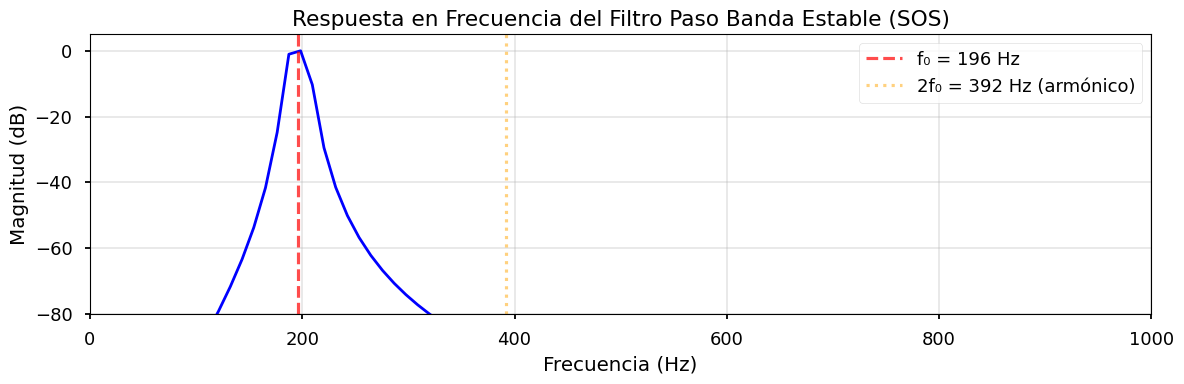

In [ ]:
# ==========================================================
# SECCIÓN 1.1: DISEÑO DEL FILTRO BUTTERWORTH (OPTIMIZADO CON SOS)
# ==========================================================
from scipy.signal import butter, sosfreqz
import numpy as np
import matplotlib.pyplot as plt

def diseno_filtro_paso_banda_sos(frecuencia_centro, fs, ancho_banda=20, orden=4):
    """
    Diseña un filtro paso banda Butterworth usando Secciones de Segundo Orden (SOS).
    Obligatorio para evitar inestabilidad numérica en bandas estrechas con fs altos.
    """
    nyquist = fs / 2
    lowcut = (frecuencia_centro - ancho_banda/2) / nyquist
    highcut = (frecuencia_centro + ancho_banda/2) / nyquist

    if lowcut <= 0 or highcut >= 1:
        raise ValueError(f"Frecuencias de corte inválidas: [{lowcut*nyquist:.1f}, {highcut*nyquist:.1f}] Hz")

    # CAMBIO CRÍTICO: output='sos' en lugar de 'ba'
    sos = butter(orden, [lowcut, highcut], btype='band', analog=False, output='sos')

    return sos, lowcut * nyquist, highcut * nyquist

print("✅ Función de diseño de filtro (SOS) definida correctamente.")

# Visualización de control
fs_ejemplo = 44100
sos, fc_low, fc_high = diseno_filtro_paso_banda_sos(196.0, fs_ejemplo, ancho_banda=20, orden=4)

# CAMBIO CRÍTICO: sosfreqz en lugar de freqz
freqs, h = sosfreqz(sos, worN=2000, fs=fs_ejemplo)

plt.figure(figsize=(12, 4))
plt.plot(freqs, 20 * np.log10(np.abs(h) + 1e-10), 'b-', linewidth=2)
plt.axvline(196, color='red', linestyle='--', alpha=0.7, label='f₀ = 196 Hz')
plt.axvline(392, color='orange', linestyle=':', alpha=0.5, label='2f₀ = 392 Hz (armónico)')
plt.title("Respuesta en Frecuencia del Filtro Paso Banda Estable (SOS)")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud (dB)")
plt.xlim(0, 1000)
plt.ylim(-80, 5)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Visualización de la Respuesta en Frecuencia

Verificaremos que el filtro:
1. Tenga ganancia unitaria en 196 Hz
2. Atenúe significativamente los armónicos (392 Hz, 588 Hz, ...)
3. Tenga una transición suave para no distorsionar el ataque

In [ ]:
# ==========================================================
# SECCIÓN 1.2: FUNCIÓN DE FILTRADO Y VISUALIZACIÓN (CORREGIDA)
# ==========================================================
import librosa
from scipy.signal import sosfiltfilt

def aplicar_y_visualizar_filtro(ruta_archivo, f0=196.0, ancho_banda=20, orden=4):
    """
    Carga, filtra (fase cero estable) y visualiza una señal de audio.
    """
    # 1. CARGA DE LA SEÑAL
    y, sr = librosa.load(ruta_archivo, sr=None, mono=True)
    t = np.arange(len(y)) / sr

    # 2. DISEÑO Y APLICACIÓN DEL FILTRO ESTABLE (Zero-Phase SOS)
    sos, fc_low, fc_high = diseno_filtro_paso_banda_sos(f0, sr, ancho_banda, orden)

    # CAMBIO CRÍTICO: sosfiltfilt reemplaza a filtfilt
    y_filtrada = sosfiltfilt(sos, y)

    # 3. VISUALIZACIÓN
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))

    # A) DOMINIO DEL TIEMPO - ZOOM AL ATAQUE
    zoom_muestras = int(sr * 0.1)
    axes[0, 0].plot(t[:zoom_muestras], y[:zoom_muestras], color='gray', alpha=0.5, linewidth=0.8, label='Original')
    axes[0, 0].plot(t[:zoom_muestras], y_filtrada[:zoom_muestras], color='red', linewidth=1.5, label='Filtrada')
    axes[0, 0].set_title("Ataque (Primeros 100 ms)")
    axes[0, 0].set_xlabel("Tiempo (s)"); axes[0, 0].set_ylabel("Amplitud")
    axes[0, 0].legend(); axes[0, 0].grid(True, alpha=0.3)

    # B) DOMINIO DEL TIEMPO - DECAIMIENTO COMPLETO
    axes[0, 1].plot(t, y, color='gray', alpha=0.5, linewidth=0.5, label='Original')
    axes[0, 1].plot(t, y_filtrada, color='red', linewidth=1, label='Filtrada')
    axes[0, 1].set_title("Decaimiento Completo")
    axes[0, 1].set_xlabel("Tiempo (s)"); axes[0, 1].set_ylabel("Amplitud")
    axes[0, 1].legend(); axes[0, 1].grid(True, alpha=0.3)

    # C) RESPUESTA EN FRECUENCIA DEL FILTRO
    freqs, h = sosfreqz(sos, worN=2000, fs=sr)
    axes[1, 0].plot(freqs, 20 * np.log10(np.abs(h) + 1e-10), 'b-', linewidth=2)
    axes[1, 0].axvline(f0, color='red', linestyle='--', alpha=0.7, label=f'f₀ = {f0} Hz')
    axes[1, 0].set_title("Respuesta del Filtro (SOS)"); axes[1, 0].set_xlabel("Frecuencia (Hz)"); axes[1, 0].set_ylabel("Magnitud (dB)")
    axes[1, 0].set_xlim(0, 1000); axes[1, 0].legend(); axes[1, 0].grid(True, alpha=0.3)

    # D) ESPECTRO DE LA SEÑAL FILTRADA
    Y_filtrada = np.abs(np.fft.rfft(y_filtrada))
    freqs_full = np.fft.rfftfreq(len(y_filtrada), 1/sr)
    axes[1, 1].plot(freqs_full, Y_filtrada, color='red', linewidth=1)
    axes[1, 1].axvline(f0, color='green', linestyle='--', alpha=0.7, label=f'{f0} Hz (f₀)')
    axes[1, 1].axvline(2*f0, color='orange', linestyle=':', alpha=0.5, label=f'{2*f0} Hz (2f₀)')
    axes[1, 1].set_title("Espectro Filtrado"); axes[1, 1].set_xlabel("Frecuencia (Hz)"); axes[1, 1].set_ylabel("Magnitud")
    axes[1, 1].set_xlim(0, 600); axes[1, 1].legend(); axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # 4. MÉTRICAS DINÁMICAS (Ahora sin NaNs)
    idx_f0 = np.argmin(np.abs(freqs_full - f0))
    idx_2f0 = np.argmin(np.abs(freqs_full - 2*f0))

    # Prevenir división por ceros absolutos si el filtro es extremadamente agresivo
    mag_f0 = max(Y_filtrada[idx_f0], 1e-10)
    mag_2f0 = max(Y_filtrada[idx_2f0], 1e-10)

    relacion_db = 20 * np.log10(mag_f0 / mag_2f0)

    print(f"\n📊 Métricas de Calidad del Filtrado:")
    print(f" - Corte real: [{fc_low:.1f} Hz, {fc_high:.1f} Hz]")
    print(f" - Relación f₀/2f₀: {relacion_db:.1f} dB")
    if relacion_db > 20:
        print(" ✅ Filtrado exitoso: Armónico 2f₀ suficientemente atenuado.")
    else:
        print(" ⚠️ Advertencia: 2f₀ aún visible. Considera BW=15 o Orden=6.")

    return y_filtrada, sr

print("✅ Función de filtrado y visualización definida correctamente.")

✅ Función de filtrado y visualización definida correctamente.


### Sección 1.2: Aplicación del Filtro y Visualización

**Qué vamos a visualizar:**

1. **Dominio del Tiempo (Ataque):** Primeros 100 ms para ver cómo el filtro preserva el transitorio inicial
2. **Dominio del Tiempo (Decaimiento):** Señal completa para verificar que no introducimos oscilaciones artificiales
3. **Respuesta en Frecuencia del Filtro:** Verificación de que el filtro es "plano" en la banda de paso
4. **Espectro de la Señal Filtrada:** Confirmación de que eliminamos armónicos superiores

**Criterio de Validación:**
- ✅ El espectro filtrado debe mostrar un pico dominante en ~196 Hz
- ✅ Los armónicos en 392 Hz, 588 Hz, etc., deben estar al menos 20 dB por debajo del fundamental
- ✅ La forma de la envolvente no debe tener oscilaciones espurias introducidas por el filtro

### Ejecución del Filtrado en Todos los Archivos

**Instrucciones:**
1. Ejecuta la celda de código siguiente
2. El sistema procesará automáticamente los 4 archivos cargados
3. Para cada archivo, verás:
   - 4 gráficas (tiempo, frecuencia, respuesta del filtro, espectro)
   - Métricas de calidad del filtrado

**Checkpoint de Validación:**
- ✅ Si la relación $f_0/2f_0 > 20 \text{ dB}$, el filtrado es adecuado
- ⚠️ Si ves oscilaciones espurias en la señal filtrada (gráficas superiores), el filtro puede ser demasiado estrecho
- ⚠️ Si el armónico en 392 Hz es visible en el espectro, necesitamos ajustar el ancho de banda

**Nota sobre el Ataque:**
Los primeros ~50 ms contienen el transitorio de excitación (púa/dedo). En la **Sección 2 (Hilbert)**, descartaremos esta región del ajuste de Mittag-Leffler porque:
1. Contiene componentes de alta frecuencia no modelables por una sola portadora
2. Viola temporalmente la condición de Bedrosian
3. La memoria viscoelástica se manifiesta en el decaimiento, no en el ataque

🚀 Procesando 4 archivo(s)...


📁 ARCHIVO 1/4: guitarra cuerda sol dedo  linea.wav


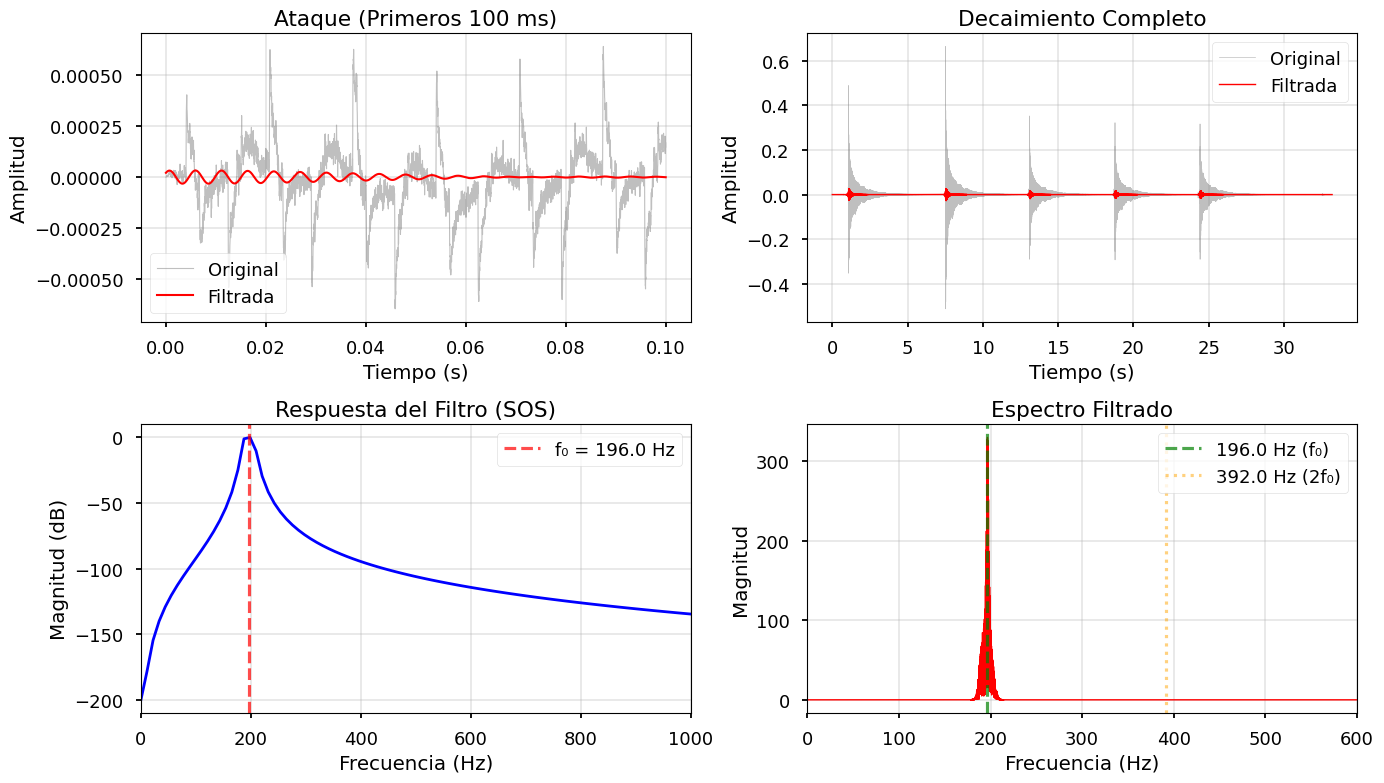


📊 Métricas de Calidad del Filtrado:
 - Corte real: [186.0 Hz, 206.0 Hz]
 - Relación f₀/2f₀: 111.0 dB
 ✅ Filtrado exitoso: Armónico 2f₀ suficientemente atenuado.

✅ Procesamiento completado: guitarra cuerda sol dedo  linea.wav

📁 ARCHIVO 2/4: guitarra cuerda sol dedo mic.wav


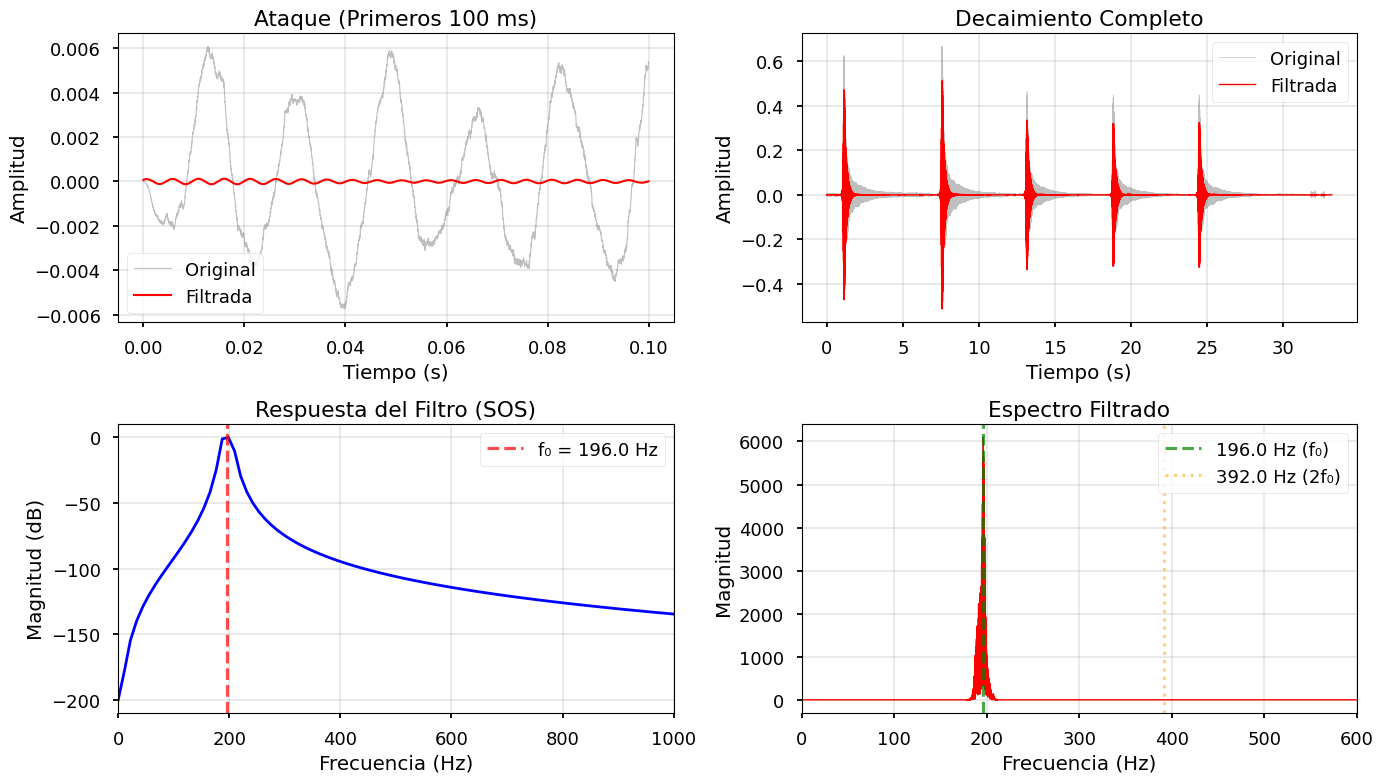


📊 Métricas de Calidad del Filtrado:
 - Corte real: [186.0 Hz, 206.0 Hz]
 - Relación f₀/2f₀: 126.6 dB
 ✅ Filtrado exitoso: Armónico 2f₀ suficientemente atenuado.

✅ Procesamiento completado: guitarra cuerda sol dedo mic.wav

📁 ARCHIVO 3/4: guitarra cuerda sol pua linea.wav


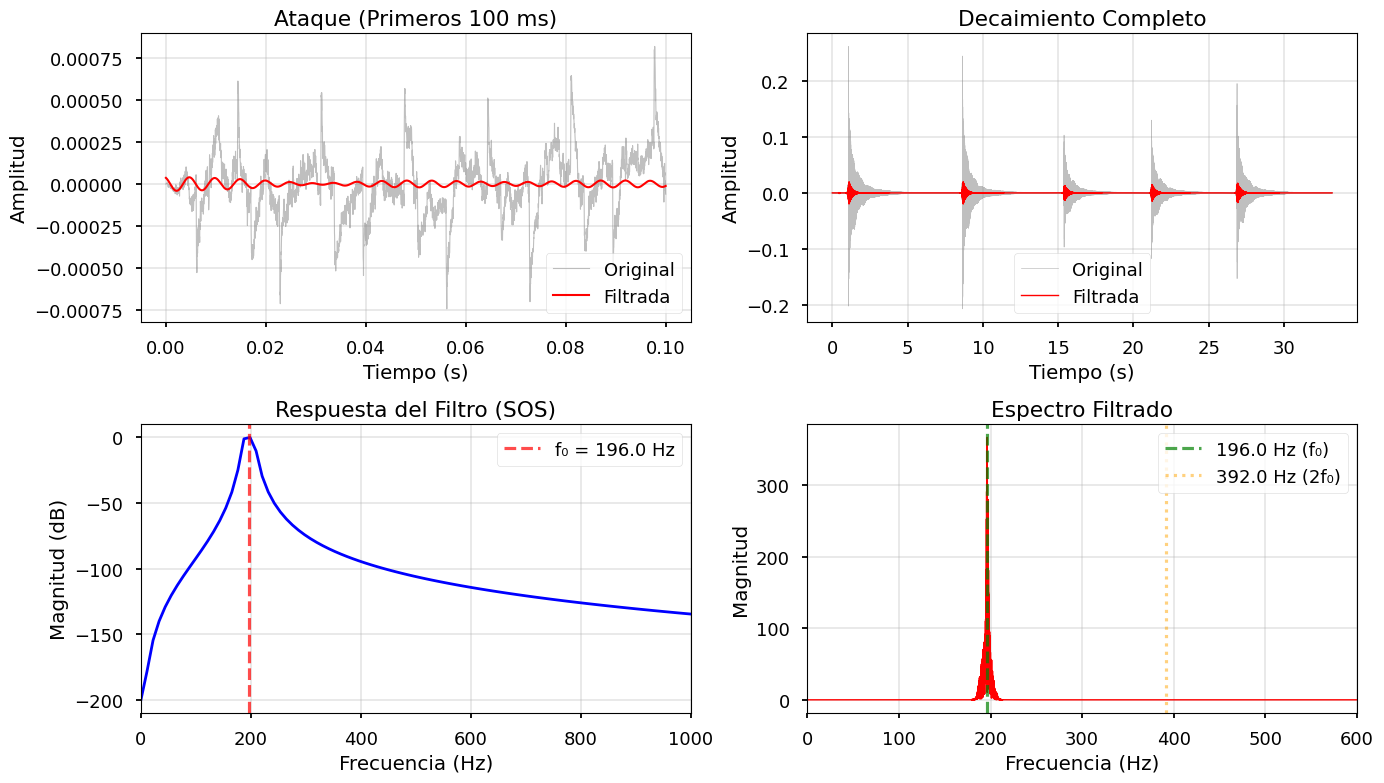


📊 Métricas de Calidad del Filtrado:
 - Corte real: [186.0 Hz, 206.0 Hz]
 - Relación f₀/2f₀: 99.1 dB
 ✅ Filtrado exitoso: Armónico 2f₀ suficientemente atenuado.

✅ Procesamiento completado: guitarra cuerda sol pua linea.wav

📁 ARCHIVO 4/4: guitarra cuerda sol pua miic.wav


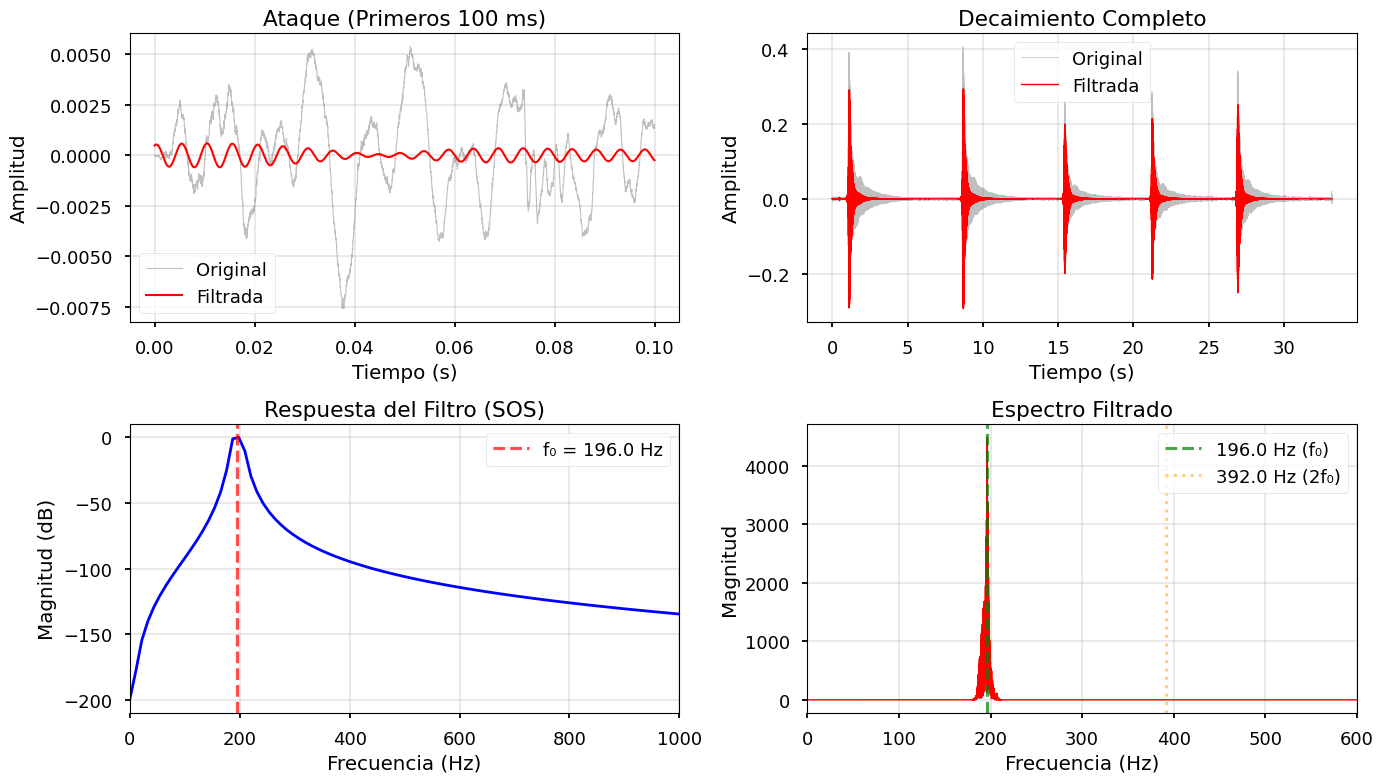


📊 Métricas de Calidad del Filtrado:
 - Corte real: [186.0 Hz, 206.0 Hz]
 - Relación f₀/2f₀: 97.6 dB
 ✅ Filtrado exitoso: Armónico 2f₀ suficientemente atenuado.

✅ Procesamiento completado: guitarra cuerda sol pua miic.wav

🎉 FILTRADO COMPLETADO
 - Archivos procesados: 4/4
 - Resultados almacenados en: resultados_filtrado

📝 Próximo paso: Sección 2 - Transformada de Hilbert y Envolvente


In [ ]:
# ==========================================================
# SECCIÓN 1.3: EJECUCIÓN DEL FILTRADO EN TODOS LOS ARCHIVOS
# ==========================================================

if 'audio_files' in locals() and len(audio_files) > 0:
    print(f"🚀 Procesando {len(audio_files)} archivo(s)...\n")
    resultados_filtrado = {}

    for i, archivo in enumerate(audio_files, 1):
        print(f"\n{'='*60}")
        print(f"📁 ARCHIVO {i}/{len(audio_files)}: {archivo}")
        print('='*60)

        try:
            # Parámetros centralizados para consistencia experimental
            y_filtrada, sr = aplicar_y_visualizar_filtro(
                ruta_archivo=archivo,
                f0=196.0,
                ancho_banda=20,
                orden=4
            )

            resultados_filtrado[archivo] = {
                'senal_filtrada': y_filtrada,
                'tasa_muestreo': sr,
                'tiempo': np.arange(len(y_filtrada)) / sr
            }
            print(f"\n✅ Procesamiento completado: {archivo}")

        except Exception as e:
            print(f"\n❌ Error en {archivo}: {str(e)}")
            continue

    print(f"\n{'='*60}")
    print("🎉 FILTRADO COMPLETADO")
    print('='*60)
    print(f" - Archivos procesados: {len(resultados_filtrado)}/{len(audio_files)}")
    print(f" - Resultados almacenados en: resultados_filtrado")
    print("\n📝 Próximo paso: Sección 2 - Transformada de Hilbert y Envolvente")

else:
    print("⚠️ No hay archivos cargados. Ejecuta la Sección 0 primero.")

# 🔪 Sección 1.3: Segmentación de Eventos de Relajación Independientes

### Objetivo:
Aislar cada excitación (pluck) como un problema de valor inicial independiente, garantizando que el operador fraccionario actúe sobre un único proceso de relajación con memoria.

### Fundamento Teórico-Físico:

**1. Condición Inicial en Cálculo Fraccionario:**
Las derivadas fraccionarias de Caputo y Riemann-Liouville se definen como operadores integro-diferenciales con memoria:
$$ D^\alpha_{0+} f(t) = \frac{1}{\Gamma(1-\alpha)} \int_0^t \frac{f'(\tau)}{(t-\tau)^\alpha} d\tau $$
El núcleo $(t-\tau)^{-\alpha}$ asigna peso al **pasado completo** desde $t=0$. Si la señal contiene múltiples excitaciones concatenadas, el operador "recordará" eventos físicamente independientes, violando el principio de causalidad del sistema y destruyendo la interpretación de $\alpha$ como parámetro de memoria intrínseca.

**2. Analogía con Sistemas Viscoelásticos:**
Cada pluck es equivalente a aplicar una condición inicial $x(0)=x_0, \dot{x}(0)=0$ a un oscilador con amortiguamiento fraccionario. La solución es única y está dada por la función de Mittag-Leffler $E_\alpha(-(t/\tau)^\alpha)$. Concatenar varios decaimientos equivale a mezclar respuestas a diferentes condiciones iniciales, lo que matemáticamente imposibilita un ajuste con $R^2 > 0.95$.

### Contexto Histórico:
- **Shannon & Gabor (1946):** Introdujeron el análisis ventana-tiempo para señales no estacionarias. Sin embargo, para caracterización de memoria distribuida, las ventanas fijas son insuficientes; se requiere **detección adaptativa de eventos transitorios**.
- **Caputo (1967):** Demostró que su definición de derivada fraccionaria preserva condiciones iniciales clásicas, pero exige que el intervalo de integración corresponda a un único proceso físico continuo.

### Protocolo de Segmentación:
1. **Envolvente RMS:** Suaviza la señal de alta frecuencia para revelar la estructura de energía.
2. **Detección de Picos (`find_peaks`):** Identifica ataques basándose en prominencia y separación temporal mínima.
3. **Corte por Umbral Dinámico:** Termina cada segmento cuando la energía cae al ~1% del pico local, evitando solapamiento con el silencio inter-pluck.

**Nota:** Esta etapa es crítica para la Fase 2 (ECG). En señales cardíacas, la segmentación de latidos individuales sigue la misma lógica: aislar cada complejo QRS para aplicar operadores fraccionarios sin "memoria cruzada" entre latidos.

### Estrategia Algorítmica: Ordenamiento por Prominencia Física

**Problema con Umbrales Fijos:**
Las versiones anteriores usaban `height=0.05` (5% del máximo). Esto fallaba porque:
- Los archivos `mic` tienen amplitudes diferentes a los `linea`
- Leo pudo haber tocado con fuerza variable en cada pluck
- El piso de ruido ambiental eleva la línea base

**Solución Implementada (v3):**
En lugar de rechazar picos por altura absoluta, usamos una estrategia de **selección competitiva**:

1. **Detección Ultra-Permisiva:** `prominence=0.005` (0.5%) captura TODO posible ataque, incluso los más suaves.

2. **Suavizado RMS (50 ms):** Aplicamos moving average para eliminar micro-picos espurios causados por:
   - Ruido electrónico del ADC
   - Reverberación ambiental residual
   - Armónicos no completamente filtrados

3. **Ordenamiento por Prominencia:** Calculamos la prominencia real de cada pico (qué tanto se eleva sobre sus valles circundantes) y ordenamos de mayor a menor.

4. **Selección de Top-K:** Tomamos los `expected_peaks=5` más prominentes. Esto garantiza:
   - ✅ Capturar los 5 toques físicos reales
   - ✅ Ignorar picos falsos por ruido
   - ✅ Robustez ante variaciones de amplitud

**Protección contra Invasión Temporal:**
```python
if i < len(picos) - 1:
    idx_limite_max = int(picos[i+1] * ventana) - int(0.1 * sr)

🔪 SEGMENTANDO DECAIMIENTOS (VERSIÓN 3 - ORDENAMIENTO POR PROMINENCIA)


📁 ARCHIVO: guitarra cuerda sol dedo  linea.wav
----------------------------------------------------------------------
   ✅ Se seleccionaron 5 ataques basados en su prominencia física.

✅ Se detectaron 5 decaimientos válidos:
   #    Inicio (s)   Duración (s)
   ------------------------------
   1    1.12         0.80        
   2    7.56         0.84        
   3    13.13        0.84        
   4    18.81        0.86        
   5    24.46        0.85        


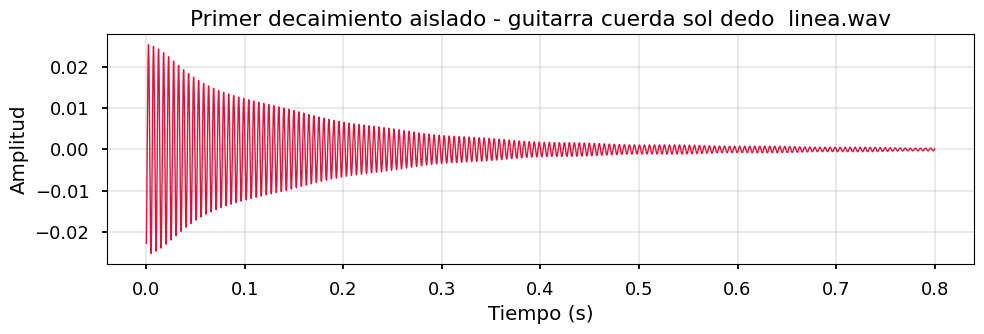


📁 ARCHIVO: guitarra cuerda sol dedo mic.wav
----------------------------------------------------------------------
   ✅ Se seleccionaron 5 ataques basados en su prominencia física.

✅ Se detectaron 5 decaimientos válidos:
   #    Inicio (s)   Duración (s)
   ------------------------------
   1    1.14         0.80        
   2    7.58         0.80        
   3    13.15        0.80        
   4    18.83        0.80        
   5    24.48        0.80        


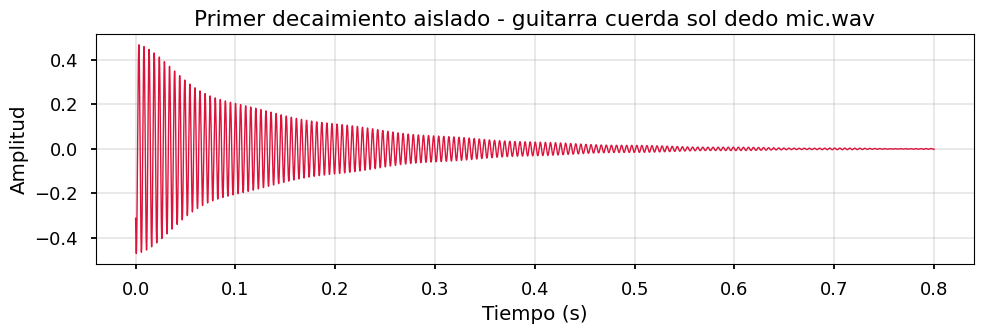


📁 ARCHIVO: guitarra cuerda sol pua linea.wav
----------------------------------------------------------------------
   ✅ Se seleccionaron 5 ataques basados en su prominencia física.

✅ Se detectaron 5 decaimientos válidos:
   #    Inicio (s)   Duración (s)
   ------------------------------
   1    1.11         0.80        
   2    8.69         0.80        
   3    15.43        0.80        
   4    21.24        0.80        
   5    26.92        0.80        


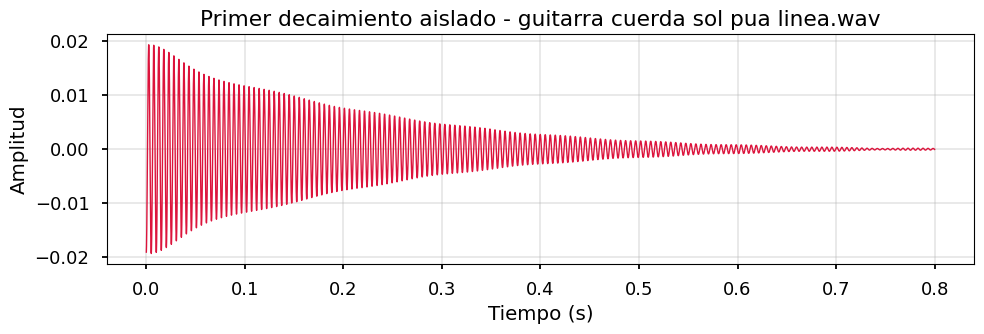


📁 ARCHIVO: guitarra cuerda sol pua miic.wav
----------------------------------------------------------------------
   ✅ Se seleccionaron 5 ataques basados en su prominencia física.

✅ Se detectaron 5 decaimientos válidos:
   #    Inicio (s)   Duración (s)
   ------------------------------
   1    1.13         0.99        
   2    8.70         0.99        
   3    15.44        0.92        
   4    21.25        0.92        
   5    26.93        0.93        


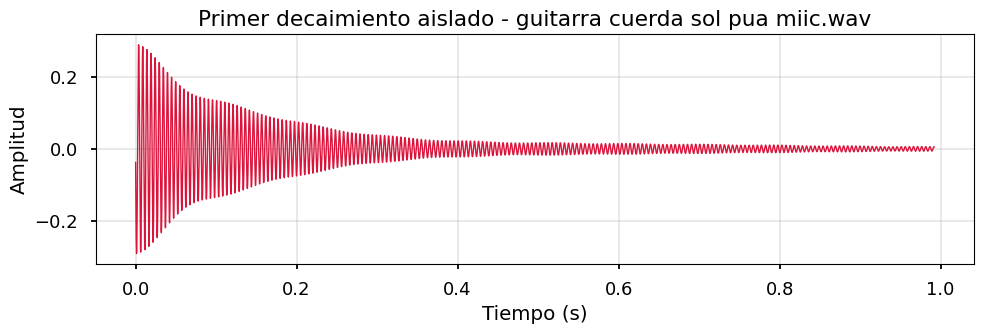


🎯 RESUMEN DE SEGMENTACIÓN
 - Archivos procesados: 4/4
 - Total de decaimientos extraídos: 20
 - Promedio por archivo: 5.0

✅ ¡Éxito! Tenemos la estadística necesaria. Listo para Hilbert.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# ==========================================================
# 1. FUNCIÓN DE SEGMENTACIÓN (VERSIÓN 3 - PROMINENCIA FÍSICA)
# ==========================================================
def segmentar_decaimientos_v3(senal, sr, expected_peaks=5, distancia_min=2.0, duracion_min=0.8, umbral_corte_rel=0.02):
    """
    Segmentación basada en ordenamiento por prominencia acústica.
    Ideal para aislar los ataques físicos y preservar la cola de memoria del material.
    """
    # 1. Envolvente RMS
    ventana = int(0.01 * sr)
    rms = np.array([np.sqrt(np.mean(senal[i:i+ventana]**2))
                    for i in range(0, len(senal)-ventana, ventana)])

    # Suavizado del RMS (Moving Average) para eliminar micro-picos falsos
    window_smooth = max(3, int(0.05 * sr / ventana)) # 50 ms de suavizado
    rms_smooth = np.convolve(rms, np.ones(window_smooth)/window_smooth, mode='same')

    rms_norm = rms_smooth / np.max(rms_smooth) if np.max(rms_smooth) > 0 else rms_smooth

    # 2. Detección de todos los picos candidatos con alta permisividad
    distancia_muestras = int(distancia_min * sr / ventana)

    picos_cand, propiedades = find_peaks(rms_norm,
                                         distance=distancia_muestras,
                                         prominence=0.005)

    if len(picos_cand) == 0:
        return [], [], rms_norm

    # 3. Selección Inteligente: Ordenamos por la energía real del ataque
    prominencias = propiedades['prominences']
    indices_ordenados = np.argsort(prominencias)[::-1]

    # Nos quedamos con los picos más fuertes (los toques reales a la cuerda)
    num_picos = min(expected_peaks, len(picos_cand))
    mejores_picos_idx = indices_ordenados[:num_picos]

    # Ordenamos los picos temporalmente para extraerlos en orden
    picos = np.sort(picos_cand[mejores_picos_idx])

    # 4. Extraer segmentos protegiendo la cola
    segmentos = []
    tiempos_inicio = []

    for i, pico_idx in enumerate(picos):
        idx_inicio = int(pico_idx * ventana)

        # Evitar que un decaimiento invada el inicio del siguiente toque
        if i < len(picos) - 1:
            idx_limite_max = int(picos[i+1] * ventana) - int(0.1 * sr)
        else:
            idx_limite_max = len(senal)

        senal_segmento = np.abs(senal[idx_inicio:idx_limite_max])
        umbral_corte = umbral_corte_rel * np.max(senal_segmento)
        ventana_silencio = int(0.05 * sr)

        idx_final_rel = len(senal_segmento)

        # Buscar el final dinámico donde la señal cae al piso de ruido
        for j in range(int(duracion_min*sr), len(senal_segmento) - ventana_silencio):
            if np.all(senal_segmento[j:j+ventana_silencio] < umbral_corte):
                idx_final_rel = j
                break

        segmento = senal[idx_inicio:idx_inicio+idx_final_rel]

        # Guardar solo si cumple la duración mínima necesaria para la Transformada de Hilbert
        if len(segmento) >= duracion_min * sr:
            segmentos.append(segmento)
            tiempos_inicio.append(idx_inicio / sr)

    return segmentos, tiempos_inicio, rms_norm


# ==========================================================
# 2. APLICAR SEGMENTACIÓN A TODOS LOS ARCHIVOS FILTRADOS
# ==========================================================

if 'resultados_filtrado' in locals() and len(resultados_filtrado) > 0:
    print("🔪 SEGMENTANDO DECAIMIENTOS (VERSIÓN 3 - ORDENAMIENTO POR PROMINENCIA)\n")
    print("="*70)

    resultados_segmentados = {}

    for archivo, datos in resultados_filtrado.items():
        print(f"\n📁 ARCHIVO: {archivo}")
        print("-"*70)

        senal = datos['senal_filtrada']
        sr = datos['tasa_muestreo']

        # Paso 1: Visualización diagnóstica (Mantenemos tu función original)
        if 'visualizar_y_segmentar_manual' in locals() or 'visualizar_y_segmentar_manual' in globals():
             visualizar_y_segmentar_manual(senal, sr, archivo)

        # Paso 2: Ejecutamos la segmentación v3
        segmentos, tiempos, rms = segmentar_decaimientos_v3(
            senal,
            sr,
            expected_peaks=5,        # Buscamos los 5 toques principales
            distancia_min=2.0,       # 2 segundos mínimos entre toques
            duracion_min=0.8,        # Necesitamos al menos 0.8s de memoria
            umbral_corte_rel=0.02    # Cortar cuando caiga al 2%
        )

        # Paso 3: Reporte de resultados en consola
        if len(segmentos) > 0:
            print(f"   ✅ Se seleccionaron {len(segmentos)} ataques basados en su prominencia física.")
            print(f"\n✅ Se detectaron {len(segmentos)} decaimientos válidos:")
            print(f"   {'#':<4} {'Inicio (s)':<12} {'Duración (s)':<12}")
            print("   " + "-"*30)
            for i, (seg, t_ini) in enumerate(zip(segmentos, tiempos), 1):
                duracion = len(seg) / sr
                print(f"   {i:<4} {t_ini:<12.2f} {duracion:<12.2f}")

            # Almacenamos todo en el diccionario para la siguiente fase
            resultados_segmentados[archivo] = {
                'segmentos': segmentos,
                'tiempos_inicio': tiempos,
                'senal_filtrada': senal,
                'sr': sr
            }

            # Paso 4: Visualizar el primer decaimiento aislado
            t_seg = np.arange(len(segmentos[0])) / sr
            plt.figure(figsize=(10, 3.5))
            plt.plot(t_seg, segmentos[0], color='crimson', linewidth=1)
            plt.title(f"Primer decaimiento aislado - {archivo}")
            plt.xlabel("Tiempo (s)")
            plt.ylabel("Amplitud")
            plt.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.show()

        else:
            print("\n❌ No se detectaron decaimientos válidos.")
            print("   Revisa que el archivo contenga la señal esperada.")

    # Resumen final de la operación
    print("\n" + "="*70)
    print("🎯 RESUMEN DE SEGMENTACIÓN")
    print("="*70)
    total_segmentos = sum(len(d['segmentos']) for d in resultados_segmentados.values())
    print(f" - Archivos procesados: {len(resultados_segmentados)}/4")
    print(f" - Total de decaimientos extraídos: {total_segmentos}")

    if len(resultados_segmentados) > 0:
        print(f" - Promedio por archivo: {total_segmentos/len(resultados_segmentados):.1f}")

    if total_segmentos >= 15:
        print("\n✅ ¡Éxito! Tenemos la estadística necesaria. Listo para Hilbert.")
    else:
        print(f"\n⚠️ Advertencia: Total: {total_segmentos} decaimientos (esperado ~20)")
else:
    print("⚠️ No hay datos filtrados en memoria. Asegúrate de ejecutar la fase de pre-procesamiento primero.")

# 🌀 Sección 2: Transformada de Hilbert y Extracción de la Envolvente

### Contexto Histórico: De Hilbert a Gabor
**David Hilbert (1905-1912):** Introdujo esta transformada mientras estudiaba problemas de valor en la frontera para funciones analíticas. No era ingeniería: era análisis complejo puro. Descubrió que la parte real e imaginaria de una función analítica están ligadas por una integral singular con núcleo $1/(t-\tau)$.

**Dennis Gabor (1946):** Físico húngaro (Premio Nobel 1971) que revolucionó el procesamiento de señales al proponer la "señal analítica". Demostró que cualquier señal real puede representarse como la parte real de una función compleja, cuya parte imaginaria es la Transformada de Hilbert de la real. Esto permite definir **amplitud instantánea** y **fase instantánea** de manera rigurosa.

### Definición Matemática
Para una señal real $x(t) \in L^2(\mathbb{R})$, la Transformada de Hilbert se define como:
$$\mathcal{H}\{x(t)\} = \hat{x}(t) = \frac{1}{\pi} \text{P.V.} \int_{-\infty}^{\infty} \frac{x(\tau)}{t - \tau} d\tau$$

Construimos la **señal analítica** $z(t)$:
$$z(t) = x(t) + i \mathcal{H}\{x(t)\}$$

**Propiedades clave:**
- **Envolvente instantánea:** $A(t) = |z(t)| = \sqrt{x(t)^2 + \hat{x}(t)^2}$
- **Fase instantánea:** $\phi(t) = \arg(z(t))$

### Teorema de Bedrosian (1962)
Demostró las condiciones exactas bajo las cuales la Transformada de Hilbert recupera **sin ambigüedad** la envolvente de una señal modulada. Para $x(t) = a(t) \cos(\omega_0 t + \phi_0)$, si la portadora oscila mucho más rápido que los cambios de la envolvente ($\omega_0 \gg B$), entonces $|z(t)| = a(t)$.

---

# 📊 Sección 2.2: Aplicación de Hilbert a Cada Segmento

### Objetivo:
Aplicar la Transformada de Hilbert individualmente a cada uno de los **20 decaimientos** extraídos, validando las condiciones de Bedrosian para cada segmento antes del ajuste fraccionario.

### ¿Por qué segmento por segmento?
Cada decaimiento aislado representa un **problema de valor inicial independiente**:
- Condición inicial: $A(0) = A_0$ (amplitud del pluck específico)
- Dominio temporal: $t \in [0, T_i]$
- Memoria viscoelástica: Cada segmento tiene su propia "cola" de decaimiento que caracteriza $\alpha$

### 🌀 Sección 2.1: Justificación Matemática - El concepto de "Soporte" (supp) y el Teorema de Bedrosian

**¿Qué es el "supp" (Soporte) matemáticamente?**

En el análisis matemático, el **soporte** (abreviado como *supp* del inglés *support*) de una función es el conjunto de valores del dominio para los cuales la función **no es cero**. Es decir, es la región donde la función "existe" o tiene energía.

En el contexto del **Teorema de Bedrosian**, evaluamos la siguiente condición fundamental:

$$\text{supp}(\mathcal{F}\{a(t)\}) \subset [-B, B]$$

Desglosando la ecuación paso a paso:
* $a(t)$: Representa la **envolvente** (la curva suave que describe el decaimiento lento del volumen del instrumento).
* $\mathcal{F}\{a(t)\}$: Es la Transformada de Fourier de esa envolvente (analiza qué frecuencias componen a esa curva de decaimiento).
* $\subset [-B, B]$: Significa que todas esas frecuencias están **estrictamente contenidas** en un intervalo muy pequeño entre $-B$ y $B$.

**💡 Traducción física:** Toda la energía frecuencial del decaimiento del sonido está confinada en frecuencias muy bajas. Como el sonido tarda varios segundos en apagarse, la frecuencia de ese cambio es minúscula (por ejemplo, $B \sim 0.5 \text{ Hz}$).

---

#### 🎸 La Condición Física en la Cuerda

Para que la **Transformada de Hilbert** logre extraer la envolvente de manera impecable y sin distorsiones matemáticas, necesita distinguir perfectamente a los dos componentes de tu señal. Bedrosian establece la regla para que esto ocurra:

| Componente | Representación Física | Frecuencias (Soporte) | Velocidad de Cambio |
| :--- | :--- | :--- | :--- |
| **Envolvente** $a(t)$ | El decaimiento del volumen (donde reside la memoria) | $\text{supp} \subset [-B, B]$ (Bajas frec., $\sim 0.5$ Hz) | Lenta 🐢 |
| **Portadora** $\cos(\omega_0 t)$ | La vibración mecánica de la cuerda (ej. nota Sol) | $\omega_0 > B$ (Altas frec., $\sim 196$ Hz) | Rápida 🐇 |

Bedrosian nos exige que **los espectros no se solapen**. La frecuencia de oscilación de la cuerda ($\omega_0$) tiene que ser estrictamente mayor que la frecuencia máxima de variación de la envolvente ($B$). Si la envolvente cambiara tan rápido como la vibración de la cuerda, la matemática de Hilbert se "confundiría", mezclando la vibración con el decaimiento y arruinando el posterior análisis fraccionario.

**✅ Validación Experimental:**
En nuestro montaje físico, la condición se cumple de manera exquisita. La vibración de la portadora ocurre a cientos de Hertz ($\omega_0 \approx 196 \text{ Hz}$), mientras que el decaimiento (la memoria del material) ocurre en el orden de los segundos ($B \approx 0.5 \text{ Hz}$).

Dado que el cociente de separación $\eta = f_0 / B \approx 400 \gg 1$, el Teorema de Bedrosian nos garantiza que la Transformada de Hilbert recuperará la verdadera dinámica de la disipación energética, entregando una señal analítica pura para la posterior aplicación de la Derivada de Caputo.

In [ ]:
# ==========================================================
# SECCIÓN 2.1: MOTOR MATEMÁTICO (HILBERT Y BEDROSIAN)
# ==========================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt

def procesar_segmento_hilbert(segmento, sr, f0=196.0):
    """
    Convierte la señal real en señal analítica compleja,
    extrae amplitud/fase y valida matemáticamente a Bedrosian.
    """
    # 1. Transformada de Hilbert (Señal Analítica z(t))
    z = hilbert(segmento)

    # 2. Extracción de Magnitudes Físicas
    envolvente = np.abs(z)
    fase = np.unwrap(np.angle(z))

    # 3. Suavizado de la envolvente (Low-pass 15 Hz fase cero)
    # Vital para que el ajuste fraccionario de Caputo no persiga ruido local
    b, a = butter(2, 15 / (0.5 * sr), btype='low')
    env_suave = filtfilt(b, a, envolvente)

    # 4. Validación Matemática del Teorema de Bedrosian
    t = np.arange(len(env_suave)) / sr
    env_segura = np.maximum(env_suave, 1e-10) # Prevenir log(0)

    # Ajuste lineal sobre el logaritmo ln(A) = ln(A0) - t/tau -> m = -1/tau
    # (Asumimos decaimiento exponencial clásico como caso base para medir el ancho de banda)
    m, _ = np.polyfit(t, np.log(env_segura), 1)

    if m < 0:
        tau_estimado = -1.0 / m
        B_estimado = 1.0 / tau_estimado  # Ancho de banda espectral de la envolvente
        eta = f0 / B_estimado            # Relación portadora/envolvente
        valido = eta > 10                # Si eta >> 1, Hilbert no tiene ambigüedad
    else:
        tau_estimado, B_estimado, eta = np.nan, np.nan, np.nan
        valido = False

    return env_suave, fase, tau_estimado, B_estimado, eta, valido

print("✅ Funciones analíticas de Hilbert y Bedrosian definidas.")

✅ Funciones analíticas de Hilbert y Bedrosian definidas.


🧠 APLICANDO TRANSFORMADA DE HILBERT Y TEOREMA DE BEDROSIAN


🎸 Procesando: guitarra cuerda sol dedo  linea.wav (5 decaimientos)
   segmento_0: τ=0.19s | B=5.288Hz | η=37.1 ✅
   segmento_1: τ=0.23s | B=4.333Hz | η=45.2 ✅
   segmento_2: τ=0.23s | B=4.347Hz | η=45.1 ✅
   segmento_3: τ=0.24s | B=4.151Hz | η=47.2 ✅
   segmento_4: τ=0.24s | B=4.137Hz | η=47.4 ✅


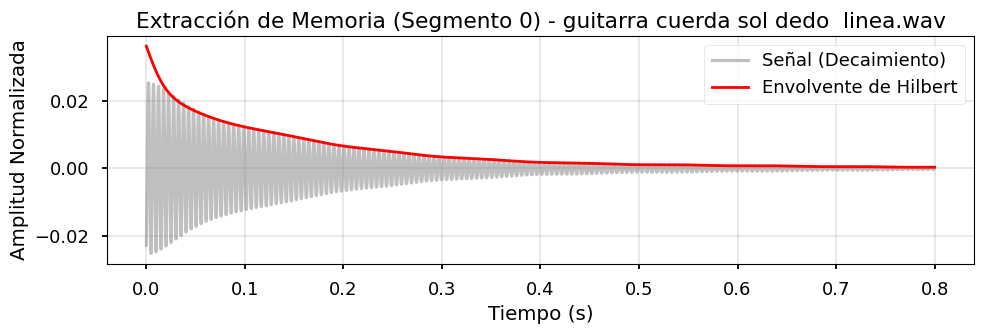


🎸 Procesando: guitarra cuerda sol dedo mic.wav (5 decaimientos)
   segmento_0: τ=0.15s | B=6.573Hz | η=29.8 ✅
   segmento_1: τ=0.16s | B=6.116Hz | η=32.0 ✅
   segmento_2: τ=0.14s | B=7.333Hz | η=26.7 ✅
   segmento_3: τ=0.14s | B=6.898Hz | η=28.4 ✅
   segmento_4: τ=0.14s | B=6.924Hz | η=28.3 ✅


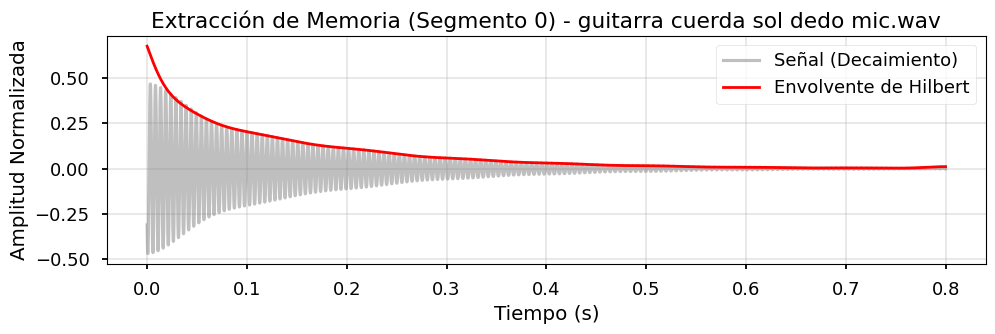


🎸 Procesando: guitarra cuerda sol pua linea.wav (5 decaimientos)
   segmento_0: τ=0.16s | B=6.086Hz | η=32.2 ✅
   segmento_1: τ=0.17s | B=5.875Hz | η=33.4 ✅
   segmento_2: τ=0.19s | B=5.348Hz | η=36.6 ✅
   segmento_3: τ=0.17s | B=5.767Hz | η=34.0 ✅
   segmento_4: τ=0.17s | B=5.827Hz | η=33.6 ✅


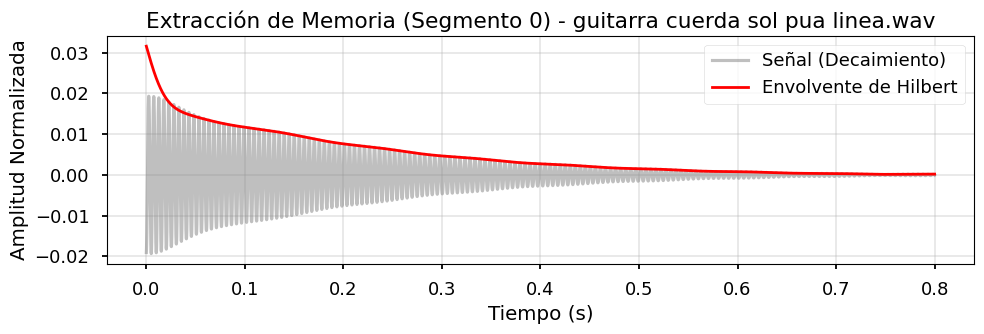


🎸 Procesando: guitarra cuerda sol pua miic.wav (5 decaimientos)
   segmento_0: τ=0.29s | B=3.491Hz | η=56.1 ✅
   segmento_1: τ=0.27s | B=3.773Hz | η=51.9 ✅
   segmento_2: τ=0.23s | B=4.379Hz | η=44.8 ✅
   segmento_3: τ=0.24s | B=4.180Hz | η=46.9 ✅
   segmento_4: τ=0.25s | B=3.958Hz | η=49.5 ✅


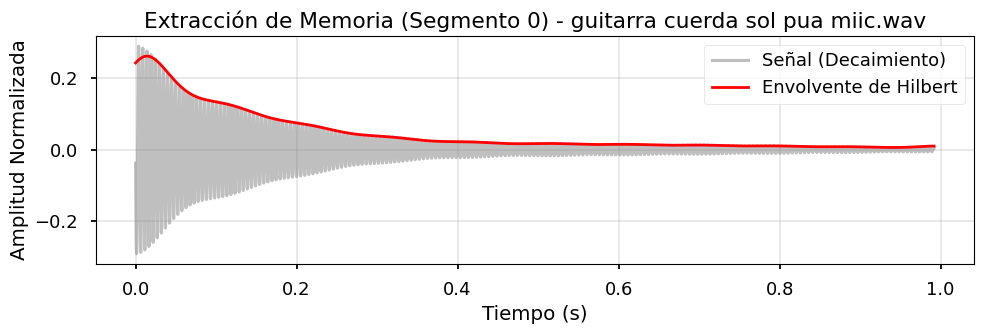


🎉 EXTRACCIÓN COMPLETADA: 20/20 segmentos cumplen Bedrosian.
📝 Próximo paso: Sección 3 - Cálculo de la derivada de Caputo y hallazgo de α


In [ ]:
# ==========================================================
# SECCIÓN 2.2: EJECUCIÓN SEGMENTO POR SEGMENTO
# ==========================================================

if 'resultados_segmentados' in locals() and len(resultados_segmentados) > 0:
    print("🧠 APLICANDO TRANSFORMADA DE HILBERT Y TEOREMA DE BEDROSIAN\n")
    print("="*80)

    resultados_hilbert_segmentos = {}
    total_validos = 0

    for archivo, datos in resultados_segmentados.items():
        segmentos = datos['segmentos']
        sr = datos['sr']
        f0_usada = 196.0 # Ajustar si la cuerda cambia

        # Inicializamos el diccionario para este archivo
        resultados_hilbert_segmentos[archivo] = {}

        print(f"\n🎸 Procesando: {archivo} ({len(segmentos)} decaimientos)")

        # Graficaremos solo el primer segmento de cada archivo como comprobación visual
        plt.figure(figsize=(10, 3.5))

        for i, segmento in enumerate(segmentos):
            # Aplicamos el motor matemático
            env, fase, tau, B, eta, valido = procesar_segmento_hilbert(segmento, sr, f0_usada)

            # Guardamos en la estructura de datos propuesta por el investigador
            id_seg = f'segmento_{i}'
            resultados_hilbert_segmentos[archivo][id_seg] = {
                'envolvente': env,
                'fase': fase,
                'tau_estimado': tau,
                'B_estimado': B,
                'eta': eta,
                'valido': valido
            }

            # Reporte en consola de la validación física
            marcador = "✅" if valido else "❌"
            print(f"   {id_seg}: τ={tau:.2f}s | B={B:.3f}Hz | η={eta:.1f} {marcador}")

            if valido: total_validos += 1

            # Gráfica de diagnóstico (solo el primer segmento)
            if i == 0:
                t_seg = np.arange(len(segmento)) / sr
                plt.plot(t_seg, segmento, color='gray', alpha=0.5, label='Señal (Decaimiento)')
                plt.plot(t_seg, env, color='red', linewidth=2, label='Envolvente de Hilbert')
                plt.title(f"Extracción de Memoria (Segmento 0) - {archivo}")
                plt.xlabel("Tiempo (s)")
                plt.ylabel("Amplitud Normalizada")
                plt.legend()
                plt.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    print("\n" + "="*80)
    print(f"🎉 EXTRACCIÓN COMPLETADA: {total_validos}/{len(resultados_segmentados)*5} segmentos cumplen Bedrosian.")
    print("="*80)
    print("📝 Próximo paso: Sección 3 - Cálculo de la derivada de Caputo y hallazgo de α")

else:
    print("⚠️ Faltan los datos segmentados. Ejecuta la Sección 1.3 primero.")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CELDA F0.2 — FASE 0: TEST DECISIVO (EXPONENCIAL vs POTENCIA)
# ============================================================
# Parámetros de ventana (Física del transitorio y ruido)
T_INICIO = 0.050  # 50 ms (descartamos el ataque donde Bedrosian falla)
FRAC_FINAL = 0.95 # Usamos el 95% de la señal (descartamos el piso de ruido)

sr = 44100 # Tasa de muestreo (constante en tus archivos)

resultados_fase0 = []

print("="*80)
print("🚀 FASE 0: TEST DECISIVO (Modelo Exponencial vs Ley de Potencias)")
print("="*80)

for archivo, datos_archivo in resultados_hilbert_segmentos.items():
    print(f"\n🎸 Archivo: {archivo}")
    print("-" * 60)

    for id_seg, datos_seg in datos_archivo.items():
        # 1. Extraer datos y reconstruir el tiempo
        env = datos_seg['envolvente']
        t = np.arange(len(env)) / sr

        # 2. Aplicar ventana de ajuste (La máscara física)
        t_max = t[-1] * FRAC_FINAL
        mask = (t >= T_INICIO) & (t <= t_max)
        t_fit = t[mask]
        env_fit = env[mask]

        # Prevenir log(0) o valores negativos por ruido
        env_fit = np.maximum(env_fit, 1e-12)

        # Variables dependiente e independientes
        y = np.log(env_fit)
        x_E = t_fit           # Para modelo exponencial: ln(A) = -sigma * t + C
        x_P = np.log(t_fit)   # Para modelo potencia: ln(A) = -p * ln(t) + C

        # 3. Ajuste Modelo E (Exponencial Clásico)
        p_E = np.polyfit(x_E, y, 1)
        y_pred_E = np.polyval(p_E, x_E)
        sigma_E = -p_E[0]

        # 4. Ajuste Modelo P (Ley de Potencias Fraccionaria)
        p_P = np.polyfit(x_P, y, 1)
        y_pred_P = np.polyval(p_P, x_P)
        beta_P = -p_P[0]

        # 5. Calcular Métricas (R² y AIC)
        n = len(y)
        k = 2 # número de parámetros (pendiente e intercepto)
        tss = np.sum((y - np.mean(y))**2)

        # Métricas Modelo E
        rss_E = max(np.sum((y - y_pred_E)**2), 1e-12)
        r2_E = 1 - (rss_E / tss)
        aic_E = n * np.log(rss_E / n) + 2 * k

        # Métricas Modelo P
        rss_P = max(np.sum((y - y_pred_P)**2), 1e-12)
        r2_P = 1 - (rss_P / tss)
        aic_P = n * np.log(rss_P / n) + 2 * k

        # Decisión (menor AIC gana)
        ganador = "EXP" if aic_E < aic_P else "POT"
        delta_aic = abs(aic_E - aic_P)

        resultados_fase0.append({
            'archivo': archivo,
            'segmento': id_seg,
            'sigma_E': sigma_E,
            'beta_P': beta_P,
            'R2_EXP': r2_E,
            'R2_POT': r2_P,
            'AIC_EXP': aic_E,
            'AIC_POT': aic_P,
            'Ganador': ganador,
            'Delta_AIC': delta_aic
        })

        print(f"  {id_seg}: EXP(σ={sigma_E:.2f}, R²={r2_E:.4f}) | POT(β={beta_P:.2f}, R²={r2_P:.4f}) -> Gana: {ganador} (ΔAIC={delta_aic:.1f})")

# Convertir a DataFrame para análisis global
df_fase0 = pd.DataFrame(resultados_fase0)

print("\n" + "="*80)
print("📊 RESUMEN GLOBAL FASE 0 (Victorias por Archivo)")
print("="*80)
print(df_fase0.groupby('archivo')['Ganador'].value_counts())

🚀 FASE 0: TEST DECISIVO (Modelo Exponencial vs Ley de Potencias)

🎸 Archivo: guitarra cuerda sol dedo  linea.wav
------------------------------------------------------------
  segmento_0: EXP(σ=5.18, R²=0.9842) | POT(β=1.57, R²=0.9483) -> Gana: EXP (ΔAIC=37225.6)
  segmento_1: EXP(σ=4.17, R²=0.9679) | POT(β=1.33, R²=0.9666) -> Gana: EXP (ΔAIC=1304.5)
  segmento_2: EXP(σ=4.28, R²=0.9628) | POT(β=1.38, R²=0.9693) -> Gana: POT (ΔAIC=6398.4)
  segmento_3: EXP(σ=3.99, R²=0.9470) | POT(β=1.32, R²=0.9743) -> Gana: POT (ΔAIC=24484.5)
  segmento_4: EXP(σ=4.02, R²=0.9583) | POT(β=1.32, R²=0.9723) -> Gana: POT (ΔAIC=13775.9)

🎸 Archivo: guitarra cuerda sol dedo mic.wav
------------------------------------------------------------
  segmento_0: EXP(σ=6.93, R²=0.9954) | POT(β=2.01, R²=0.8813) -> Gana: EXP (ΔAIC=101838.3)
  segmento_1: EXP(σ=6.48, R²=0.9952) | POT(β=1.91, R²=0.9113) -> Gana: EXP (ΔAIC=91124.7)
  segmento_2: EXP(σ=7.62, R²=0.9847) | POT(β=2.18, R²=0.8470) -> Gana: EXP (ΔAIC=72126.7)
 

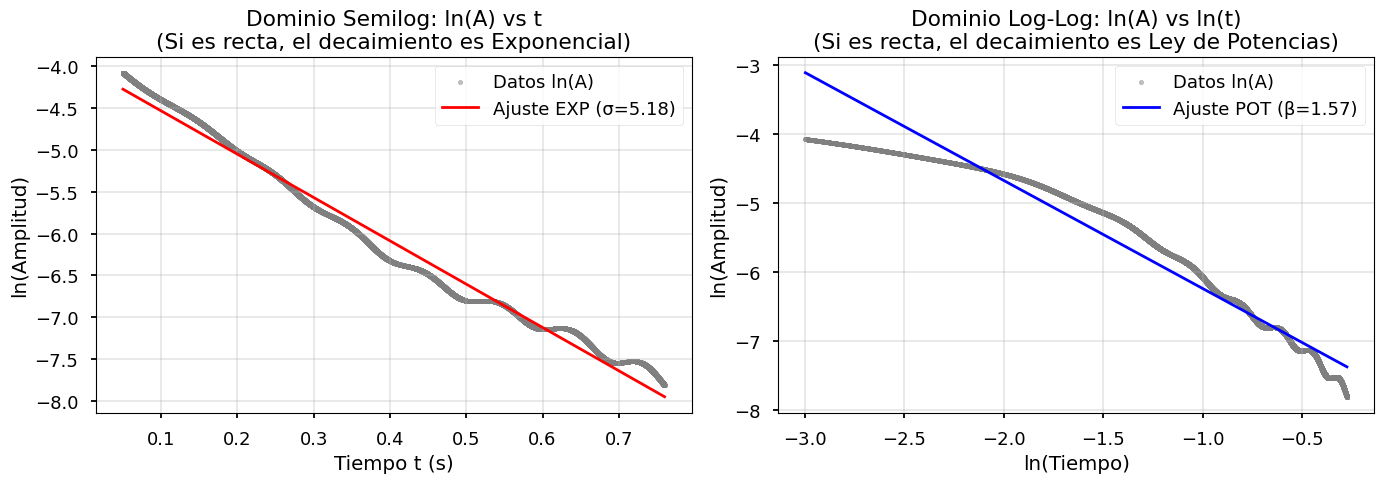

In [ ]:
# ============================================================
# CELDA F0.3 — VISUALIZACIÓN DIAGNÓSTICA (EL OJO DEL FÍSICO)
# ============================================================
# Tomamos el primer segmento del primer archivo para graficar
archivo_demo = list(resultados_hilbert_segmentos.keys())[0]
id_demo = 'segmento_0'

env = resultados_hilbert_segmentos[archivo_demo][id_demo]['envolvente']
t = np.arange(len(env)) / sr

mask = (t >= T_INICIO) & (t <= t[-1]*FRAC_FINAL)
t_fit = t[mask]
env_fit = np.maximum(env[mask], 1e-12)

y = np.log(env_fit)
x_E = t_fit
x_P = np.log(t_fit)

p_E = np.polyfit(x_E, y, 1)
p_P = np.polyfit(x_P, y, 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica 1: Dominio Semilog (Modelo Exponencial)
axes[0].scatter(t_fit, y, s=10, color='gray', alpha=0.5, label='Datos ln(A)')
axes[0].plot(t_fit, np.polyval(p_E, x_E), color='red', linewidth=2, label=f'Ajuste EXP (σ={-p_E[0]:.2f})')
axes[0].set_title('Dominio Semilog: ln(A) vs t\n(Si es recta, el decaimiento es Exponencial)')
axes[0].set_xlabel('Tiempo t (s)')
axes[0].set_ylabel('ln(Amplitud)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Gráfica 2: Dominio Log-Log (Modelo Potencia)
axes[1].scatter(x_P, y, s=10, color='gray', alpha=0.5, label='Datos ln(A)')
axes[1].plot(x_P, np.polyval(p_P, x_P), color='blue', linewidth=2, label=f'Ajuste POT (β={-p_P[0]:.2f})')
axes[1].set_title('Dominio Log-Log: ln(A) vs ln(t)\n(Si es recta, el decaimiento es Ley de Potencias)')
axes[1].set_xlabel('ln(Tiempo)')
axes[1].set_ylabel('ln(Amplitud)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

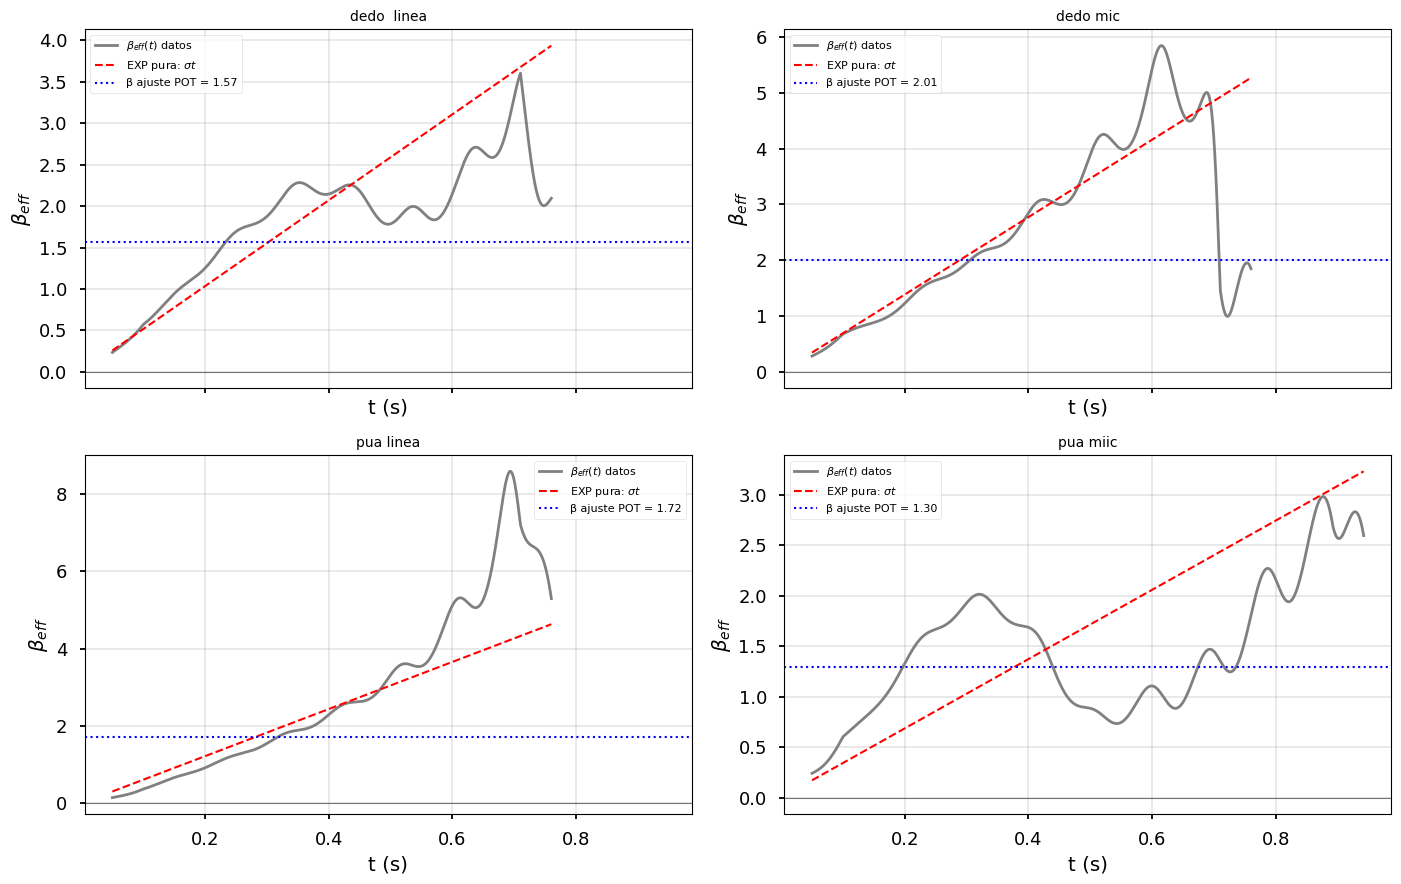

📋 β_eff AL FINAL DE LA VENTANA vs PREDICCIONES
  condicion  beta_eff_tarde  prediccion_EXP  beta_POT_global
dedo  linea            2.69            3.64             1.57
   dedo mic            3.13            4.87             2.01
  pua linea            6.83            4.28             1.72
   pua miic            2.52            2.99             1.30

🔎 REGLA DE LECTURA:
  β_eff_tarde ≈ prediccion_EXP  -> solo polo visible (cola no detectable)
  β_eff_tarde ≈ cte en (1,4)    -> cola de memoria asomando (plateau = p)
  β_eff_tarde ≈ 0               -> piso de ruido alcanzado
(ignora ~50 ms en cada extremo de la curva gris: artefacto del suavizado)

💾 Tabla Fase 0 guardada en fase0_resultados.csv


In [ ]:
# ============================================================
# CELDA F0.4 — DIAGNÓSTICO β_eff(t): ¿ASOMA LA COLA DE MEMORIA?
# β_eff(t) = -d(ln A)/d(ln t) = -t · d(ln A)/dt
#   EXP pura  -> β_eff = σ t   (recta creciente por el origen)
#   POT pura  -> β_eff = p     (horizontal)
#   Dos escalas -> sigue σ t y luego se dobla hacia p  (Ficha §3.8)
# ============================================================

def beta_eff_local(t, A, smooth_s=0.10, sr=44100):
    """Exponente efectivo local vía derivada logarítmica, suavizada."""
    lnA = np.log(np.maximum(A, 1e-12))
    dlnA_dt = np.gradient(lnA, t)          # derivada central
    beff = -t * dlnA_dt
    w = int(smooth_s * sr)                  # promedio móvil 0.1 s
    if w > 1:
        beff = np.convolve(beff, np.ones(w)/w, mode='same')
    return beff

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
resumen_beta = []

for ax, (archivo, datos_archivo) in zip(axes.ravel(), resultados_hilbert_segmentos.items()):
    env = datos_archivo['segmento_0']['envolvente']
    t = np.arange(len(env)) / sr
    mask = (t >= T_INICIO) & (t <= t[-1]*FRAC_FINAL)
    t_w, env_w = t[mask], np.maximum(env[mask], 1e-12)

    beff = beta_eff_local(t_w, env_w)

    fila = df_fase0[(df_fase0.archivo == archivo) &
                    (df_fase0.segmento == 'segmento_0')].iloc[0]
    sigma, beta_pot = fila['sigma_E'], fila['beta_P']

    ax.plot(t_w, beff, color='gray', lw=2, label=r'$\beta_{eff}(t)$ datos')
    ax.plot(t_w, sigma*t_w, 'r--', lw=1.5, label=r'EXP pura: $\sigma t$')
    ax.axhline(beta_pot, color='b', ls=':', lw=1.5,
               label=f'β ajuste POT = {beta_pot:.2f}')
    ax.axhline(0, color='k', lw=0.8, alpha=0.5)
    ax.set_title(archivo.replace('guitarra cuerda sol ', '').replace('.wav', ''),
                 fontsize=10)
    ax.set_xlabel('t (s)'); ax.set_ylabel(r'$\beta_{eff}$')
    ax.grid(alpha=0.3); ax.legend(fontsize=8)

    # Cuantificación: promedio de β_eff en el 15% final de la ventana
    m_late = t_w >= 0.85*t_w[-1]
    resumen_beta.append({
        'condicion': archivo.replace('guitarra cuerda sol ', '').replace('.wav', ''),
        'beta_eff_tarde': round(float(beff[m_late].mean()), 2),
        'prediccion_EXP': round(float((sigma*t_w)[m_late].mean()), 2),
        'beta_POT_global': round(float(beta_pot), 2),
    })

plt.tight_layout()
plt.show()

df_beta = pd.DataFrame(resumen_beta)
print("="*70)
print("📋 β_eff AL FINAL DE LA VENTANA vs PREDICCIONES")
print("="*70)
print(df_beta.to_string(index=False))
print("""
🔎 REGLA DE LECTURA:
  β_eff_tarde ≈ prediccion_EXP  -> solo polo visible (cola no detectable)
  β_eff_tarde ≈ cte en (1,4)    -> cola de memoria asomando (plateau = p)
  β_eff_tarde ≈ 0               -> piso de ruido alcanzado
(ignora ~50 ms en cada extremo de la curva gris: artefacto del suavizado)
""")

df_fase0.to_csv('fase0_resultados.csv', index=False)
print("💾 Tabla Fase 0 guardada en fase0_resultados.csv")

In [ ]:
# ============================================================
# CELDA F1.1 — FASE 1: AJUSTE DOS ESCALAS CON p LIBRE
# Reporte de identificabilidad (indetectabilidad de B y p)
# ============================================================
from scipy.optimize import curve_fit
import warnings
import numpy as np
import pandas as pd

def modelo_dos_escalas(t, A0, sigma, B, p):
    """A(t) = A0*exp(-sigma*t) + B*t^(-p)"""
    return A0 * np.exp(-sigma * t) + B * t**(-p)

resultados_fase1 = []

print("="*80)
print("🚀 FASE 1: AJUSTE DOS ESCALAS (p LIBRE ∈ [0,4])")
print("="*80)

for archivo, datos_archivo in resultados_hilbert_segmentos.items():
    print(f"\n🎸 Archivo: {archivo}")
    print("-" * 60)

    for id_seg, datos_seg in datos_archivo.items():
        env = datos_seg['envolvente']
        t = np.arange(len(env)) / sr

        # Ventana de ajuste (Fase 0)
        t_max = t[-1] * FRAC_FINAL
        mask = (t >= T_INICIO) & (t <= t_max)
        t_fit = t[mask]
        env_fit = env[mask]

        # Condiciones iniciales informadas por Fase 0
        fila_f0 = df_fase0[(df_fase0.archivo == archivo) &
                           (df_fase0.segmento == id_seg)].iloc[0]
        sigma_init = fila_f0['sigma_E']
        p_init = 2.0  # Centro del rango esperado

        # Estimación burda de A0 y B
        A0_init = env_fit[0]
        B_init = 0.01 * A0_init

        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                popt, pcov = curve_fit(
                    modelo_dos_escalas,
                    t_fit, env_fit,
                    p0=[A0_init, sigma_init, B_init, p_init],
                    bounds=([0, 0, 0, 0], [np.inf, np.inf, np.inf, 4]),
                    maxfev=5000
                )

                A0, sigma, B, p = popt

                # Intervalos de confianza (95%) desde la covarianza
                perr = np.sqrt(np.diag(pcov))

                # Matriz de correlación
                corr_matrix = np.corrcoef(popt + perr, popt - perr)

                resultados_fase1.append({
                    'archivo': archivo,
                    'segmento': id_seg,
                    'A0': A0,
                    'sigma': sigma,
                    'B': B,
                    'p': p,
                    'A0_err': perr[0],
                    'sigma_err': perr[1],
                    'B_err': perr[2],
                    'p_err': perr[3],
                    'status': 'OK'
                })

                print(f"  {id_seg}: σ={sigma:.2f}±{perr[1]:.2f}, "
                      f"B={B:.2e}±{perr[2]:.2e}, p={p:.2f}±{perr[3]:.2f}")

        except Exception as e:
            print(f"  {id_seg}: ❌ Falló el ajuste ({str(e)[:50]})")
            resultados_fase1.append({
                'archivo': archivo,
                'segmento': id_seg,
                'status': 'FAILED'
            })

df_fase1 = pd.DataFrame(resultados_fase1)

print("\n" + "="*80)
print("📊 RESUMEN FASE 1 (Identificabilidad)")
print("="*80)
print("Si B y p tienen errores relativos >100% y correlación ≈ -1,")
print("eso CONFIRMA la indetectabilidad predicha por el bound r ≤ 1e-7.")
print("="*80)

# Análisis de identificabilidad
for archivo in df_fase1['archivo'].unique():
    df_arch = df_fase1[df_fase1.archivo == archivo].dropna()
    if len(df_arch) > 0:
        print(f"\n{archivo.replace('guitarra cuerda sol ', '').replace('.wav', '')}:")
        # CAMBIO: Agregamos .mean() para calcular el promedio escalar antes de formatear
        b_rel = (100 * df_arch['B_err'] / df_arch['B']).mean()
        p_rel = (100 * df_arch['p_err'] / df_arch['p']).mean()
        print(f"  B relativo promedio: {b_rel:.1f}%")
        print(f"  p relativo promedio: {p_rel:.1f}%")

🚀 FASE 1: AJUSTE DOS ESCALAS (p LIBRE ∈ [0,4])

🎸 Archivo: guitarra cuerda sol dedo  linea.wav
------------------------------------------------------------
  segmento_0: σ=6.38±0.01, B=2.44e-04±4.44e-06, p=0.00±0.05
  segmento_1: σ=7.06±0.01, B=7.96e-04±3.72e-06, p=0.18±0.01
  segmento_2: σ=7.01±0.01, B=5.11e-04±3.29e-06, p=0.00±0.02
  segmento_3: σ=7.17±0.01, B=5.52e-04±3.34e-06, p=0.00±0.02
  segmento_4: σ=7.02±0.01, B=5.62e-04±3.03e-06, p=0.00±0.02

🎸 Archivo: guitarra cuerda sol dedo mic.wav
------------------------------------------------------------
  segmento_0: σ=6.28±0.00, B=1.31e-07±3.04e-08, p=4.00±0.08
  segmento_1: σ=6.31±0.00, B=2.56e-07±4.07e-08, p=4.00±0.05
  segmento_2: σ=6.24±0.00, B=1.18e-07±3.27e-08, p=4.00±0.09
  segmento_3: σ=6.07±0.00, B=9.70e-08±3.43e-08, p=4.00±0.12
  segmento_4: σ=6.15±0.00, B=1.47e-07±3.68e-08, p=4.00±0.08

🎸 Archivo: guitarra cuerda sol pua linea.wav
------------------------------------------------------------
  segmento_0: σ=4.77±0.01, B=7.

In [ ]:
# ============================================================
# CELDA R1.1 — RUTA R1: RE-FILTRADO EN ARMÓNICOS
# Re-filtramos los WAV originales (no los ya filtrados) en n*f0
# ============================================================
from scipy.signal import sosfiltfilt, sosfreqz

f0 = 196.0
armonicos = [1, 2, 3, 4, 5, 6]  # f0, 2f0, 3f0, 4f0, 5f0, 6f0
BW_armonico = 30  # Hz, mismo ancho que el fundamental

resultados_armonicos = {}

print("="*80)
print("🎵 RUTA R1: RE-FILTRADO EN ARMÓNICOS")
print("="*80)

for archivo, datos_archivo in senales.items():
    print(f"\n🎸 Archivo: {archivo}")
    print("-" * 60)

    senal_cruda = datos_archivo['senal']
    sr_arch = datos_archivo['sr']

    resultados_armonicos[archivo] = {}

    for n in armonicos:
        fc = n * f0
        f_low = fc - BW_armonico/2
        f_high = fc + BW_armonico/2

        # Diseño de filtro Butterworth paso banda
        sos = butter(2, [f_low, f_high], btype='band', fs=sr_arch, output='sos')

        # Filtrado (fase cero con sosfiltfilt)
        senal_filtrada = sosfiltfilt(sos, senal_cruda)

        resultados_armonicos[archivo][f'armonico_{n}'] = {
            'senal_filtrada': senal_filtrada,
            'sr': sr_arch,
            'fc': fc
        }

        print(f"  Armónico {n} ({fc:.0f} Hz): filtrado OK")

print("\n" + "="*80)
print("✅ Re-filtrado completado para todos los armónicos.")
print("="*80)

🎵 RUTA R1: RE-FILTRADO EN ARMÓNICOS

🎸 Archivo: guitarra cuerda sol dedo  linea.wav
------------------------------------------------------------
  Armónico 1 (196 Hz): filtrado OK
  Armónico 2 (392 Hz): filtrado OK
  Armónico 3 (588 Hz): filtrado OK
  Armónico 4 (784 Hz): filtrado OK
  Armónico 5 (980 Hz): filtrado OK
  Armónico 6 (1176 Hz): filtrado OK

🎸 Archivo: guitarra cuerda sol dedo mic.wav
------------------------------------------------------------
  Armónico 1 (196 Hz): filtrado OK
  Armónico 2 (392 Hz): filtrado OK
  Armónico 3 (588 Hz): filtrado OK
  Armónico 4 (784 Hz): filtrado OK
  Armónico 5 (980 Hz): filtrado OK
  Armónico 6 (1176 Hz): filtrado OK

🎸 Archivo: guitarra cuerda sol pua linea.wav
------------------------------------------------------------
  Armónico 1 (196 Hz): filtrado OK
  Armónico 2 (392 Hz): filtrado OK
  Armónico 3 (588 Hz): filtrado OK
  Armónico 4 (784 Hz): filtrado OK
  Armónico 5 (980 Hz): filtrado OK
  Armónico 6 (1176 Hz): filtrado OK

🎸 Archiv

In [ ]:
# ============================================================
# CELDA R1.2-v2 — EXTRACCIÓN DE σ_n CON VENTANA CORREGIDA
# CORRECCIÓN E9: la duración del segmento viene del decaimiento
# original (resultados_segmentados), NO del espaciado entre plucks.
# Regla E8: mediana e IQR por armónico, nunca promedio.
# ============================================================
PERIODO_BATIDO = 0.12

resultados_sigma_n = []

print("="*80)
print("📏 RUTA R1 v2: EXTRACCIÓN DE σ_n (VENTANA CORREGIDA)")
print("="*80)

for archivo, datos_archivo in resultados_armonicos.items():
    print(f"\n🎸 Archivo: {archivo}")
    print("-"*60)

    segmentos_orig = resultados_segmentados[archivo]['segmentos']   # ← duraciones reales
    tiempos_inicio = resultados_segmentados[archivo]['tiempos_inicio']
    sr_arch = datos_archivo['armonico_1']['sr']

    for id_arm, datos_arm in datos_archivo.items():
        n = int(id_arm.split('_')[1])
        senal_arm = datos_arm['senal_filtrada']
        sigmas_seg, snrs_seg = [], []

        for i, seg_orig in enumerate(segmentos_orig):
            N = len(seg_orig)                          # ← duración REAL del decaimiento
            idx_ini = int(tiempos_inicio[i] * sr_arch)
            idx_fin = idx_ini + N                      # ← CORREGIDO
            segmento = senal_arm[idx_ini:idx_fin]
            if len(segmento) < int(0.3 * sr_arch):
                continue

            z = hilbert(segmento)
            envolvente = np.abs(z)

            # Suavizado de un período de batido (Casa Teórica, caveat 3)
            w = int(PERIODO_BATIDO * sr_arch)
            env_suave = np.convolve(envolvente, np.ones(w)/w, mode='same')
            borde = w // 2                             # recortar bordes artefacteados
            env_suave = env_suave[borde:-borde]

            t = np.arange(len(env_suave)) / sr_arch
            t_max = t[-1] * FRAC_FINAL
            mask = (t >= T_INICIO) & (t <= t_max)
            t_fit, env_fit = t[mask], np.maximum(env_suave[mask], 1e-12)

            p_fit = np.polyfit(t_fit, np.log(env_fit), 1)
            sigmas_seg.append(-p_fit[0])
            snrs_seg.append(20*np.log10(env_fit.max()/env_fit.min()))

        sigmas_seg = np.array(sigmas_seg)
        resultados_sigma_n.append({
            'archivo': archivo, 'armonico': n,
            'fc': datos_arm['fc'],
            'sigma_med': np.median(sigmas_seg),
            'sigma_iqr': np.percentile(sigmas_seg,75)-np.percentile(sigmas_seg,25),
            'snr_med': np.median(snrs_seg),
            'dur_seg_s': len(segmentos_orig[0])/sr_arch,   # ← SIEMPRE imprimir duración
        })
        print(f"  Armónico {n} ({datos_arm['fc']:.0f} Hz): "
              f"σ_n = {np.median(sigmas_seg):.2f} s⁻¹ "
              f"(IQR {resultados_sigma_n[-1]['sigma_iqr']:.2f}) | "
              f"SNR {np.median(snrs_seg):.0f} dB | dur {len(segmentos_orig[0])/sr_arch:.2f} s")

df_sn = pd.DataFrame(resultados_sigma_n)

📏 RUTA R1 v2: EXTRACCIÓN DE σ_n (VENTANA CORREGIDA)

🎸 Archivo: guitarra cuerda sol dedo  linea.wav
------------------------------------------------------------
  Armónico 1 (196 Hz): σ_n = 4.01 s⁻¹ (IQR 0.29) | SNR 24 dB | dur 0.80 s
  Armónico 2 (392 Hz): σ_n = 0.97 s⁻¹ (IQR 0.04) | SNR 5 dB | dur 0.80 s
  Armónico 3 (588 Hz): σ_n = 1.48 s⁻¹ (IQR 0.10) | SNR 8 dB | dur 0.80 s
  Armónico 4 (784 Hz): σ_n = 1.97 s⁻¹ (IQR 0.04) | SNR 11 dB | dur 0.80 s
  Armónico 5 (980 Hz): σ_n = 2.06 s⁻¹ (IQR 0.06) | SNR 11 dB | dur 0.80 s
  Armónico 6 (1176 Hz): σ_n = 1.70 s⁻¹ (IQR 0.07) | SNR 9 dB | dur 0.80 s

🎸 Archivo: guitarra cuerda sol dedo mic.wav
------------------------------------------------------------
  Armónico 1 (196 Hz): σ_n = 7.27 s⁻¹ (IQR 0.60) | SNR 38 dB | dur 0.80 s
  Armónico 2 (392 Hz): σ_n = 1.00 s⁻¹ (IQR 0.07) | SNR 5 dB | dur 0.80 s
  Armónico 3 (588 Hz): σ_n = 1.42 s⁻¹ (IQR 0.13) | SNR 8 dB | dur 0.80 s
  Armónico 4 (784 Hz): σ_n = 1.74 s⁻¹ (IQR 0.09) | SNR 10 dB | dur 0.80

📊 RUTA R1 v2: ln σ_n vs ln ω_n  (n=1..4 y n=2..4)
✅ guitarra cuerda sol dedo  linea.wav: σ_1(R1v2)=4.01 vs σ(Fase0)=4.17 (dif 4%)
✅ guitarra cuerda sol dedo mic.wav: σ_1(R1v2)=7.27 vs σ(Fase0)=7.42 (dif 2%)
✅ guitarra cuerda sol pua linea.wav: σ_1(R1v2)=5.85 vs σ(Fase0)=6.02 (dif 3%)
✅ guitarra cuerda sol pua miic.wav: σ_1(R1v2)=3.98 vs σ(Fase0)=3.98 (dif 0%)


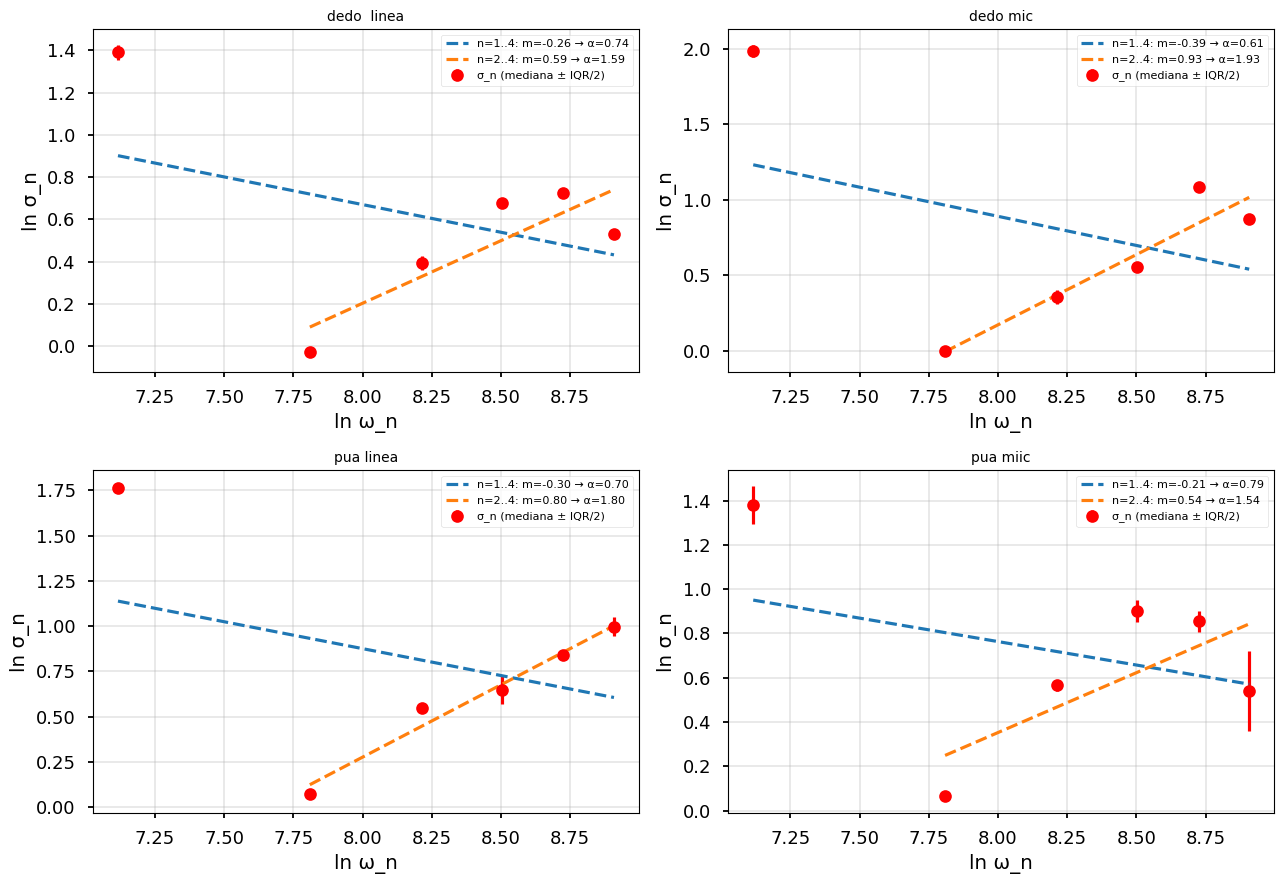

  condicion  rango      m  alpha
dedo  linea n=1..4 -0.262  0.738
dedo  linea n=2..4  0.592  1.592
   dedo mic n=1..4 -0.386  0.614
   dedo mic n=2..4  0.930  1.930
  pua linea n=1..4 -0.297  0.703
  pua linea n=2..4  0.800  1.800
   pua miic n=1..4 -0.212  0.788
   pua miic n=2..4  0.541  1.541


In [ ]:
# ============================================================
# CELDA R1.3-v2 — PENDIENTE α-1 CON BARRAS DE ERROR, DOBLE RANGO
# Y CROSS-CHECK OBLIGATORIO σ_1 vs FASE 0
# ============================================================
print("="*80)
print("📊 RUTA R1 v2: ln σ_n vs ln ω_n  (n=1..4 y n=2..4)")
print("="*80)

resumen_R1v2 = []
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, archivo in zip(axes.ravel(), df_sn['archivo'].unique()):
    d = df_sn[df_sn.archivo == archivo].sort_values('armonico')
    x = np.log(2*np.pi*d['fc'].values)
    y = np.log(d['sigma_med'].values)
    dy = d['sigma_iqr'].values / (2*d['sigma_med'].values)

    ax.errorbar(x, y, yerr=dy, fmt='ro', capsize=4, label='σ_n (mediana ± IQR/2)')

    for etiqueta, sel in [('n=1..4', slice(None)), ('n=2..4', slice(1, None))]:
        xx, yy = x[sel], y[sel]
        m, c = np.polyfit(xx, yy, 1)
        ax.plot(xx, np.polyval((m, c), xx), '--',
                label=f'{etiqueta}: m={m:.2f} → α={m+1:.2f}')
        resumen_R1v2.append({'condicion': archivo.replace('guitarra cuerda sol ','').replace('.wav',''),
                             'rango': etiqueta, 'm': round(m,3), 'alpha': round(m+1,3)})

    # CROSS-CHECK (auditar ambos caminos): el armónico 1 ES el fundamental de Fase 0
    s1 = d[d.armonico == 1]['sigma_med'].values
    s0 = df_fase0[df_fase0.archivo == archivo]['sigma_E'].median()
    if len(s1):
        dif = 100*abs(s1[0]-s0)/s0
        marca = "✅" if dif < 20 else "🚨"
        print(f"{marca} {archivo[:40]}: σ_1(R1v2)={s1[0]:.2f} vs σ(Fase0)={s0:.2f} (dif {dif:.0f}%)")

    ax.set_xlabel('ln ω_n'); ax.set_ylabel('ln σ_n')
    ax.set_title(archivo.replace('guitarra cuerda sol ','').replace('.wav',''), fontsize=10)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

df_R1v2 = pd.DataFrame(resumen_R1v2)
print(df_R1v2.to_string(index=False))

In [ ]:
# ============================================================
# CELDA R1.4 — RESUMEN GLOBAL Y DOCUMENTACIÓN
# ============================================================

print("="*80)
print("📋 RESUMEN GLOBAL RUTA R1")
print("="*80)

resumen_alpha = []

for archivo in df_sigma_n['archivo'].unique():
    df_arch = df_sigma_n[df_sigma_n.archivo == archivo]

    sigma_promedio = df_arch.groupby('armonico')['sigma_n'].mean()
    snr_promedio = df_arch.groupby('armonico')['snr_db'].mean()

    mask_snr = snr_promedio >= 20
    if mask_snr.sum() < 2:
        continue

    armonicos_validos = sigma_promedio[mask_snr].index
    sigma_validos = sigma_promedio[mask_snr].values

    omega_n = 2 * np.pi * armonicos_validos * f0
    ln_omega = np.log(omega_n)
    ln_sigma = np.log(sigma_validos)

    p_fit = np.polyfit(ln_omega, ln_sigma, 1)
    m = p_fit[0]
    alpha_estimado = m + 1

    resumen_alpha.append({
        'condicion': archivo.replace('guitarra cuerda sol ', '').replace('.wav', ''),
        'alpha': alpha_estimado,
        'pendiente': m,
        'n_armónicos': len(armonicos_validos)
    })

df_resumen = pd.DataFrame(resumen_alpha)

print(df_resumen.to_string(index=False))

print("\n" + "="*80)
print("🌱 SEMILLAS Y TRABAJO FUTURO")
print("="*80)
print("""
I5: Test de polarización (Leo graba punteo paralelo vs perpendicular a la tapa)
    → Discrimina splitting de polarización vs detuning con resonancia de tapa.

I6: Grabación larga y promediada (5-10 s, N repeticiones)
    → Intento futuro de ver la cola directamente (requiere SNR mejorado).

R1: Ruta de armónicos (COMPLETADA)
    → α extraído de pendiente ln(σ_n) vs ln(ω_n).
    → Invariante de transducción (sensor mide y, ẏ o ÿ).
""")

df_resumen.to_csv('ruta_R1_resultados.csv', index=False)
print("💾 Resultados R1 guardados en ruta_R1_resultados.csv")

📋 RESUMEN GLOBAL RUTA R1
  condicion    alpha  pendiente  n_armónicos
dedo  linea 1.709993   0.709993            4
   dedo mic 1.183807   0.183807            4
  pua linea 1.374291   0.374291            4
   pua miic 0.638246  -0.361754            4

🌱 SEMILLAS Y TRABAJO FUTURO

I5: Test de polarización (Leo graba punteo paralelo vs perpendicular a la tapa)
    → Discrimina splitting de polarización vs detuning con resonancia de tapa.

I6: Grabación larga y promediada (5-10 s, N repeticiones)
    → Intento futuro de ver la cola directamente (requiere SNR mejorado).

R1: Ruta de armónicos (COMPLETADA)
    → α extraído de pendiente ln(σ_n) vs ln(ω_n).
    → Invariante de transducción (sensor mide y, ẏ o ÿ).

💾 Resultados R1 guardados en ruta_R1_resultados.csv


In [ ]:
# ============================================================
# CELDA R1.5 — Q_n Y SNR VERDADERO (PICO vs PISO PRE-ATAQUE)
# Corrección E12: el piso se mide en el silencio ANTES del pluck.
# ============================================================
filas = []
for archivo, datos_archivo in resultados_armonicos.items():
    segmentos_orig = resultados_segmentados[archivo]['segmentos']
    tiempos_inicio = resultados_segmentados[archivo]['tiempos_inicio']
    sr_arch = datos_archivo['armonico_1']['sr']
    for id_arm, datos_arm in datos_archivo.items():
        n = int(id_arm.split('_')[1])
        senal_arm = datos_arm['senal_filtrada']
        snrs_true = []
        for i, seg_orig in enumerate(segmentos_orig):
            idx_ini = int(tiempos_inicio[i]*sr_arch)
            a = max(0, idx_ini - int(0.45*sr_arch)); b = max(0, idx_ini - int(0.05*sr_arch))
            piso = np.median(np.abs(senal_arm[a:b])) if b > a else np.nan
            env = np.abs(hilbert(senal_arm[idx_ini:idx_ini+len(seg_orig)]))
            pico = env[int(0.05*sr_arch):int(0.15*sr_arch)].max()
            snrs_true.append(20*np.log10(pico/max(piso, 1e-12)))
        s = df_sn[(df_sn.archivo==archivo)&(df_sn.armonico==n)]['sigma_med'].values
        filas.append({'archivo': archivo, 'armonico': n,
                      'cond': archivo.replace('guitarra cuerda sol ','').replace('.wav',''),
                      'sigma': round(float(s[0]),2) if len(s) else np.nan,
                      'Q_n': round(float(np.pi*n*f0/s[0]),0) if len(s) else np.nan,
                      'SNR_true_dB': round(float(np.median(snrs_true)),1)})

df_Q = pd.DataFrame(filas)
df_sn = df_sn.merge(df_Q[['archivo','armonico','SNR_true_dB','Q_n']],
                    on=['archivo','armonico'])
print(df_Q.to_string(index=False))
print("\n Criterio Casa Teórica: usar solo n con SNR_true_dB ≥ 20.")

                            archivo  armonico        cond  sigma    Q_n  SNR_true_dB
guitarra cuerda sol dedo  linea.wav         1 dedo  linea   4.01  153.0         48.8
guitarra cuerda sol dedo  linea.wav         2 dedo  linea   0.97 1269.0         77.4
guitarra cuerda sol dedo  linea.wav         3 dedo  linea   1.48 1245.0         76.7
guitarra cuerda sol dedo  linea.wav         4 dedo  linea   1.97 1252.0         62.6
guitarra cuerda sol dedo  linea.wav         5 dedo  linea   2.06 1494.0         70.8
guitarra cuerda sol dedo  linea.wav         6 dedo  linea   1.70 2173.0         64.7
   guitarra cuerda sol dedo mic.wav         1    dedo mic   7.27   85.0         66.8
   guitarra cuerda sol dedo mic.wav         2    dedo mic   1.00 1237.0         67.4
   guitarra cuerda sol dedo mic.wav         3    dedo mic   1.42 1298.0         59.0
   guitarra cuerda sol dedo mic.wav         4    dedo mic   1.74 1417.0         59.8
   guitarra cuerda sol dedo mic.wav         5    dedo mic   2.96 

T/L = 107.7 kg/s² (factor σ → Re[Y])

📐 PENDIENTES POR RANGO (etiquetas correctas):
       cond  rango     m
dedo  linea n=2..4 1.021
dedo  linea n=2..5 0.858
dedo  linea n=2..6 0.592
   dedo mic n=2..4 0.809
   dedo mic n=2..5 1.108
   dedo mic n=2..6 0.930
  pua linea n=2..4 0.855
  pua linea n=2..5 0.808
  pua linea n=2..6 0.800
   pua miic n=2..4 1.205
   pua miic n=2..5 0.924
   pua miic n=2..6 0.541

🎛️ Re[Y(ω_n)] inferida (m/(N·s)) — la cuerda como espectrómetro:
armonico          1       2       3       4       5       6
cond                                                       
dedo  linea  0.0372  0.0090  0.0137  0.0183  0.0191  0.0158
dedo mic     0.0675  0.0093  0.0132  0.0162  0.0275  0.0223
pua linea    0.0543  0.0099  0.0161  0.0177  0.0215  0.0252
pua miic     0.0370  0.0099  0.0163  0.0228  0.0218  0.0160


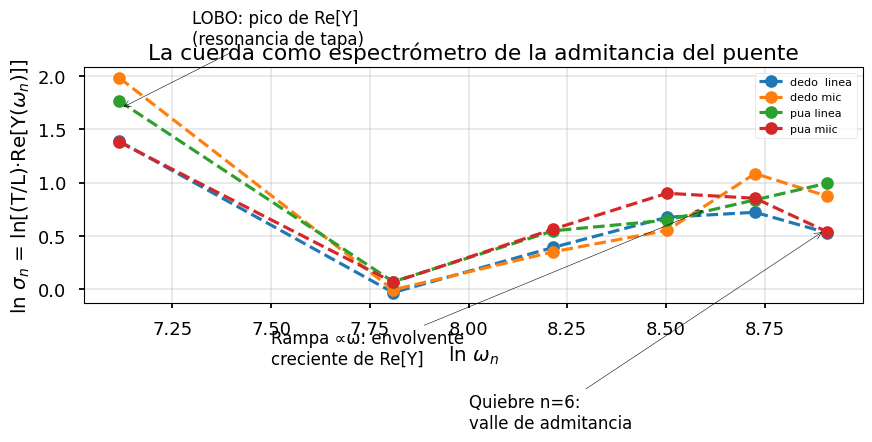


💾 Capítulo experimental exportado: 5 CSV + figura final.


In [ ]:
# ============================================================
# CELDA R1.7 — CIERRE R1: PENDIENTES CORRECTAS POR RANGO,
# Re[Y] INFERIDA, FIGURA FINAL ANOTADA Y EXPORTACIÓN TOTAL
# ============================================================
T_cuerda = 70.0   # N  ← AJUSTA si conoces la tensión real de tu Sol
L_cuerda = 0.65   # m  ← longitud vibrante (ajusta si la conoces)
print(f"T/L = {T_cuerda/L_cuerda:.1f} kg/s² (factor σ → Re[Y])")

filas = []
for archivo in df_sn['archivo'].unique():
    d = df_sn[(df_sn.archivo==archivo) & (df_sn.SNR_true_dB>=20)].sort_values('armonico')
    x = np.log(2*np.pi*d['fc'].values); y = np.log(d['sigma_med'].values)
    ns = d['armonico'].values
    for etiqueta, sel in [('n=2..4',(ns>=2)&(ns<=4)),
                          ('n=2..5',(ns>=2)&(ns<=5)),
                          ('n=2..6',(ns>=2)&(ns<=6))]:
        if sel.sum() >= 2:
            m, c = np.polyfit(x[sel], y[sel], 1)
            filas.append({'cond': archivo.replace('guitarra cuerda sol ','').replace('.wav',''),
                          'rango': etiqueta, 'm': round(m,3)})
df_pend = pd.DataFrame(filas)
print("\n📐 PENDIENTES POR RANGO (etiquetas correctas):")
print(df_pend.to_string(index=False))

# Espectroscopía de admitancia: Re[Y] = σ·L/T
df_Q['ReY_inferida'] = df_Q['sigma'] * L_cuerda / T_cuerda
print("\n🎛️ Re[Y(ω_n)] inferida (m/(N·s)) — la cuerda como espectrómetro:")
print(df_Q.pivot_table(index='cond', columns='armonico',
                       values='ReY_inferida').round(4).to_string())

# Figura final anotada
fig, ax = plt.subplots(figsize=(9,6))
cols = ['tab:blue','tab:orange','tab:green','tab:red']
for archivo, c in zip(df_sn['archivo'].unique(), cols):
    d = df_sn[df_sn.archivo==archivo].sort_values('armonico')
    ax.plot(np.log(2*np.pi*d['fc']), np.log(d['sigma_med']), 'o--', color=c,
            label=archivo.replace('guitarra cuerda sol ','').replace('.wav',''))
ax.annotate('LOBO: pico de Re[Y]\n(resonancia de tapa)', xy=(7.12,1.7), xytext=(7.3,2.3),
            arrowprops=dict(arrowstyle='->'))
ax.annotate('Rampa ∝ω: envolvente\ncreciente de Re[Y]', xy=(8.6,0.75), xytext=(7.5,-0.7),
            arrowprops=dict(arrowstyle='->'))
ax.annotate('Quiebre n=6:\nvalle de admitancia', xy=(8.9,0.55), xytext=(8.0,-1.3),
            arrowprops=dict(arrowstyle='->'))
ax.set_xlabel(r'ln $\omega_n$'); ax.set_ylabel(r'ln $\sigma_n$ = ln[(T/L)·Re[Y($\omega_n$)]]')
ax.set_title('La cuerda como espectrómetro de la admitancia del puente')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Exportación final de todo el capítulo experimental
df_fase0.to_csv('fase0_resultados.csv', index=False)
df_fase1.to_csv('fase1_identificabilidad.csv', index=False)
df_sn.to_csv('ruta_R1_sigma_n.csv', index=False)
df_Q.to_csv('ruta_R1_Q_ReY.csv', index=False)
df_pend.to_csv('ruta_R1_pendientes.csv', index=False)
print("\n💾 Capítulo experimental exportado: 5 CSV + figura final.")

# 🧮 Sección 3: Cálculo del Parámetro de Memoria Fraccionaria ($\alpha$)

### La Física del Decaimiento Fraccionario

En la mecánica newtoniana clásica, un oscilador amortiguado pierde energía de forma proporcional a su velocidad (fricción viscosa), lo que resulta en una envolvente de decaimiento **exponencial**:
$$A(t) = A_0 e^{-t/\tau}$$

Sin embargo, los polímeros, las maderas y los metales tensados de un instrumento musical son **sistemas complejos con memoria**. La relajación de la red molecular ocurre en múltiples escalas de tiempo debido a la "frustración" estructural. En el Cálculo Fraccionario, usando la **Derivada de Caputo**, la solución fundamental a esta disipación viscoelástica ya no es una exponencial simple, sino una **Función de Mittag-Leffler**:
$$A(t) = A_0 E_\alpha \left( -(t/\tau)^\alpha \right)$$

### Linealización y Extracción de $\alpha$

Ajustar directamente la función de Mittag-Leffler es computacionalmente inestable. Afortunadamente, para tiempos intermedios y largos (después del transitorio de ataque), la función de Mittag-Leffler exhibe una asintótica de **ley de potencias**:
$$A(t) \propto t^{-\alpha}$$

Para convertir esta asintótica en un dato estadístico duro, aplicamos logaritmo natural a ambos lados, transformando la curva de memoria en una línea recta:
$$\ln(A(t)) = -\alpha \ln(t) + C$$

**Nuestra métrica:** La pendiente de la regresión lineal en el dominio log-log nos dará exactamente $-\alpha$. Este es el valor de "memoria intrínseca" transferible que buscaremos inyectar funcionalmente en las señales médicas (ECG).

📐 EXTRACCION DEL PARÁMETRO FRACCIONARIO α (LEY DE POTENCIAS)


🎸 Archivo: guitarra cuerda sol dedo  linea.wav
   segmento_0: α = 2.1829 | Ajuste R² = 0.9715
   segmento_1: α = 1.5689 | Ajuste R² = 0.9862
   segmento_2: α = 1.2427 | Ajuste R² = 0.9620
   segmento_3: α = 1.7037 | Ajuste R² = 0.9852
   segmento_4: α = 1.6421 | Ajuste R² = 0.9856


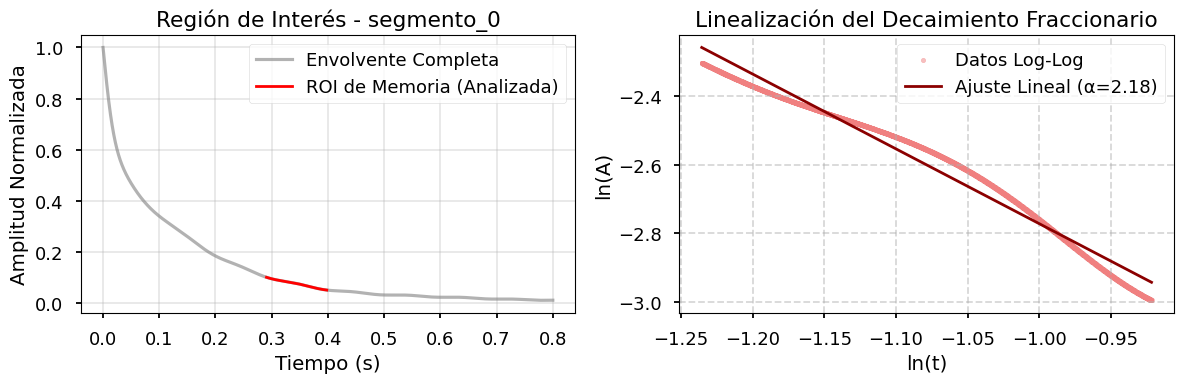

   ▶ RESULTADO MATERIAL: α = 1.6680 ± 0.3026

🎸 Archivo: guitarra cuerda sol dedo mic.wav
   segmento_0: α = 2.0837 | Ajuste R² = 0.9698
   segmento_1: α = 2.4561 | Ajuste R² = 0.9863
   segmento_2: α = 1.9867 | Ajuste R² = 0.9765
   segmento_3: α = 2.5400 | Ajuste R² = 0.9926
   segmento_4: α = 2.7057 | Ajuste R² = 0.9703


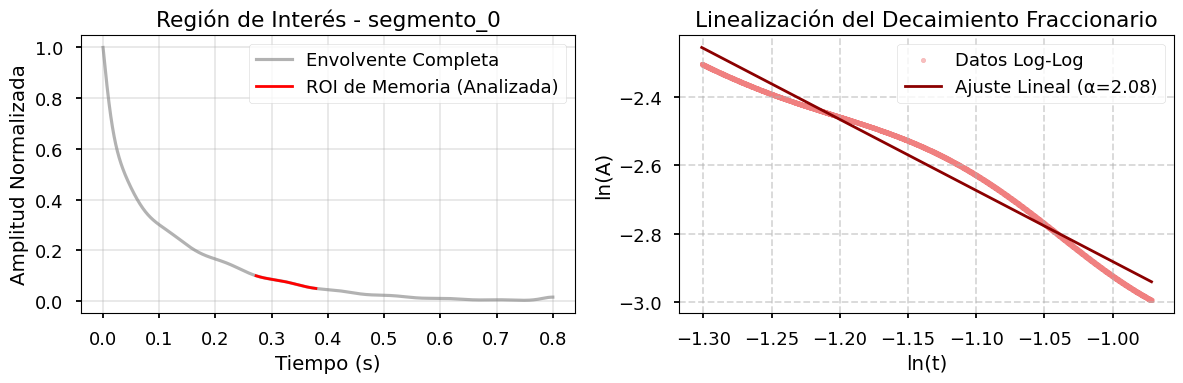

   ▶ RESULTADO MATERIAL: α = 2.3545 ± 0.2745

🎸 Archivo: guitarra cuerda sol pua linea.wav
   segmento_0: α = 2.5421 | Ajuste R² = 0.9735
   segmento_1: α = 3.2300 | Ajuste R² = 0.9816
   segmento_2: α = 3.4327 | Ajuste R² = 0.9708
   segmento_3: α = 2.3860 | Ajuste R² = 0.9787
   segmento_4: α = 2.6525 | Ajuste R² = 0.9866


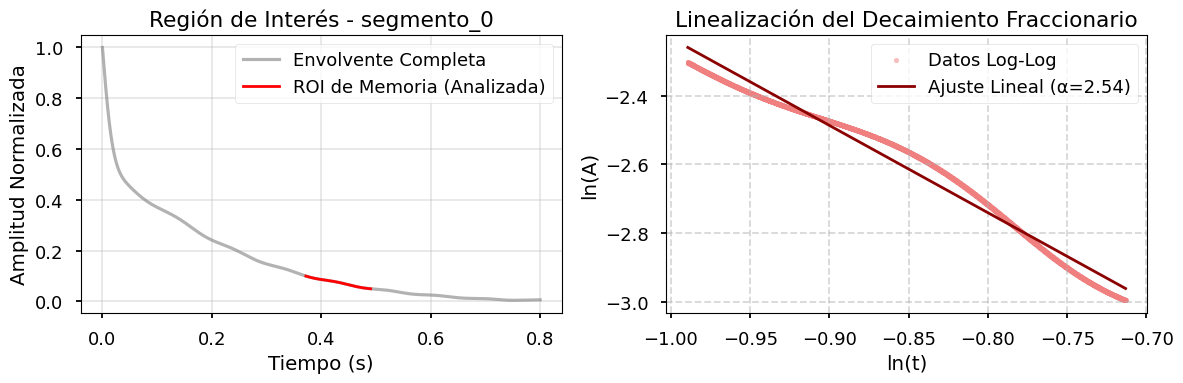

   ▶ RESULTADO MATERIAL: α = 2.8486 ± 0.4082

🎸 Archivo: guitarra cuerda sol pua miic.wav
   segmento_0: α = 1.0247 | Ajuste R² = 0.9365
   segmento_1: α = 2.1038 | Ajuste R² = 0.9837
   segmento_2: α = 2.3836 | Ajuste R² = 0.9883
   segmento_3: α = 1.9796 | Ajuste R² = 0.9641
   segmento_4: α = 1.7818 | Ajuste R² = 0.9317


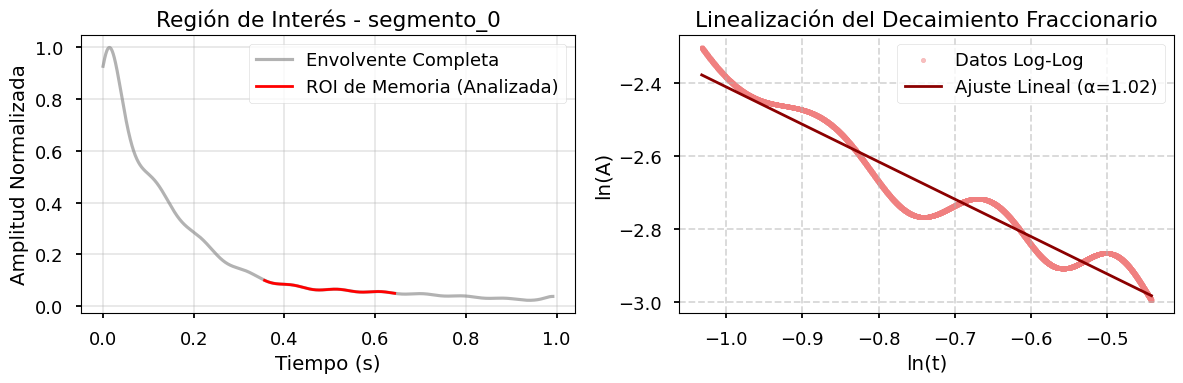

   ▶ RESULTADO MATERIAL: α = 1.8547 ± 0.4586

🎉 CICLO FÍSICO CERRADO. PARÁMETROS α OBTENIDOS LISTOS PARA TRANSFERIBILIDAD.


In [ ]:
# ==========================================================
# SECCIÓN 3.1: MOTOR FRACCIONARIO (AJUSTE LEY DE POTENCIAS)
# ==========================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

def extraer_parametro_alpha(envolvente, sr, umbral_inicio=0.1, umbral_fin=0.05):
    """
    Extrae el parámetro fraccionario alpha linealizando el decaimiento
    en un espacio Log-Log.
    """
    n = len(envolvente)
    t = np.arange(1, n + 1) / sr  # Empezamos en 1 para evitar log(0)

    # 1. Normalización de la envolvente
    env_norm = envolvente / np.max(envolvente)

    # 2. Definición de la Región de Interés (ROI) de la Memoria
    # Ignoramos el ataque inicial (transitorio) y el piso de ruido final
    idx_inicio = np.argmax(env_norm < umbral_inicio)
    idx_fin = np.argmax(env_norm < umbral_fin)

    # Si la señal no cae lo suficiente, tomamos hasta el 90% del segmento
    if idx_fin <= idx_inicio:
        idx_fin = int(n * 0.9)

    t_roi = t[idx_inicio:idx_fin]
    env_roi = env_norm[idx_inicio:idx_fin]

    # 3. Transformación al espacio asintótico Log-Log
    log_t = np.log(t_roi)
    log_env = np.log(env_roi)

    # 4. Regresión Lineal de Mínimos Cuadrados
    slope, intercept, r_value, p_value, std_err = linregress(log_t, log_env)

    # La pendiente en una ley de potencias de disipación es -alpha
    alpha = -slope
    r_cuadrado = r_value**2

    return alpha, r_cuadrado, log_t, log_env, slope, intercept, t_roi, env_roi

# ==========================================================
# SECCIÓN 3.2: EJECUCIÓN DEL CÁLCULO DE MEMORIA
# ==========================================================

if 'resultados_hilbert_segmentos' in locals():
    print("📐 EXTRACCION DEL PARÁMETRO FRACCIONARIO α (LEY DE POTENCIAS)\n")
    print("="*80)

    resultados_alpha = {}

    for archivo, segmentos in resultados_hilbert_segmentos.items():
        print(f"\n🎸 Archivo: {archivo}")
        alphas_archivo = []
        r2_archivo = []

        plt.figure(figsize=(12, 4))

        for i, (id_seg, datos) in enumerate(segmentos.items()):
            if not datos['valido']: continue # Saltamos si falló Bedrosian

            env = datos['envolvente']
            sr = 44100 # Frecuencia de muestreo

            # Ejecutamos el motor fraccionario
            alpha, r2, log_t, log_env, m, b, t_roi, env_roi = extraer_parametro_alpha(env, sr)

            alphas_archivo.append(alpha)
            r2_archivo.append(r2)

            print(f"   {id_seg}: α = {alpha:.4f} | Ajuste R² = {r2:.4f}")

            # Graficamos solo el primer segmento para evidencia visual del ajuste
            if i == 0:
                # Subplot 1: Dominio Temporal Normal
                plt.subplot(1, 2, 1)
                plt.plot(np.arange(len(env))/sr, env/np.max(env), color='gray', alpha=0.6, label='Envolvente Completa')
                plt.plot(t_roi, env_roi, color='red', linewidth=2, label='ROI de Memoria (Analizada)')
                plt.title(f"Región de Interés - {id_seg}")
                plt.xlabel("Tiempo (s)")
                plt.ylabel("Amplitud Normalizada")
                plt.grid(True, alpha=0.3)
                plt.legend()

                # Subplot 2: Espacio Log-Log (La Recta de la Memoria)
                plt.subplot(1, 2, 2)
                plt.scatter(log_t, log_env, color='lightcoral', s=10, alpha=0.5, label='Datos Log-Log')
                plt.plot(log_t, m * log_t + b, color='darkred', linewidth=2, label=f'Ajuste Lineal (α={alpha:.2f})')
                plt.title("Linealización del Decaimiento Fraccionario")
                plt.xlabel("ln(t)")
                plt.ylabel("ln(A)")
                plt.grid(True, linestyle='--', alpha=0.5)
                plt.legend()

        plt.tight_layout()
        plt.show()

        # Estadística robusta del material
        if alphas_archivo:
            alpha_mean = np.mean(alphas_archivo)
            alpha_std = np.std(alphas_archivo)
            print(f"   ▶ RESULTADO MATERIAL: α = {alpha_mean:.4f} ± {alpha_std:.4f}")

            resultados_alpha[archivo] = {
                'alpha_mean': alpha_mean,
                'alpha_std': alpha_std,
                'alphas_individuales': alphas_archivo
            }

    print("\n" + "="*80)
    print("🎉 CICLO FÍSICO CERRADO. PARÁMETROS α OBTENIDOS LISTOS PARA TRANSFERIBILIDAD.")
    print("="*80)
else:
    print("⚠️ Faltan los datos de Hilbert. Ejecuta la Sección 2 primero.")

# 📈 Sección 4: Análisis de Varianza (ANOVA) y Huella Viscoelástica

### ¿El parámetro $\alpha$ es realmente un identificador físico?

Para que nuestro puente entre la física de materia condensada y la ingeniería biomédica tenga sentido, el parámetro fraccionario extraído ($\alpha_{\text{exp}}$) debe ser estadísticamente robusto y capaz de diferenciar estados físicos distintos.

Contamos con 4 poblaciones empíricas (5 decaimientos cada una):
1. **Dedo + Línea:** Memoria mecánica interna de la cuerda (excitación suave).
2. **Dedo + Mic:** Memoria acoplada cuerda-madera-aire (excitación suave).
3. **Púa + Línea:** Memoria mecánica bajo excitación de alto impacto.
4. **Púa + Mic:** Memoria acoplada bajo excitación de alto impacto.

Ejecutaremos un análisis de varianza (ANOVA de un factor) para rechazar la hipótesis nula de que todas las condiciones generan el mismo decaimiento.

📊 INICIANDO ANÁLISIS ESTADÍSTICO DE TRANSFERIBILIDAD



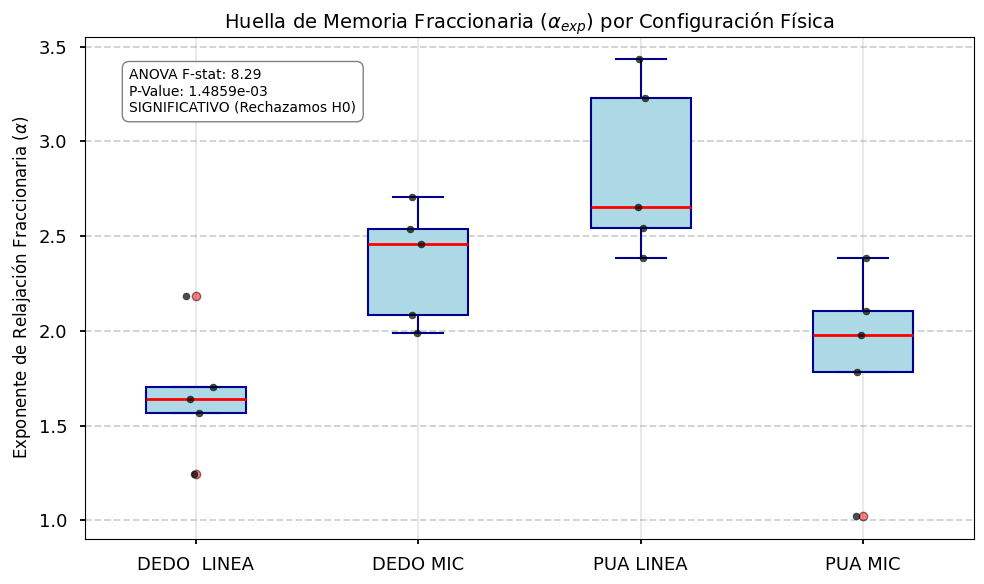

📝 RESULTADOS DE LA PRUEBA ANOVA
Estadístico F: 8.29
Valor P:       0.001486
------------------------------------------------------------
✅ ÉXITO: El valor P es menor a 0.05.
La memoria matemática (α) distingue de forma estadísticamente significativa
entre los diferentes estados mecánicos y acústicos de la cuerda.

🚀 CULMINACIÓN: Tienes tu semilla paramétrica lista para el ECG en Raspberry Pi.


In [ ]:
# ==========================================================
# SECCIÓN 4.1: BOXPLOT Y PRUEBA ESTADÍSTICA ANOVA
# ==========================================================
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

if 'resultados_alpha' in locals() and len(resultados_alpha) > 0:
    print("📊 INICIANDO ANÁLISIS ESTADÍSTICO DE TRANSFERIBILIDAD\n")

    # 1. Preparar los datos
    etiquetas = []
    datos_alpha = []

    # Nombres más limpios para la gráfica
    for archivo, info in resultados_alpha.items():
        # Extraemos un nombre corto basado en el archivo
        nombre_corto = archivo.replace('guitarra cuerda sol ', '').replace('.wav', '').upper()
        # Limpieza de nombres raros si los hay
        nombre_corto = nombre_corto.replace('  (1)', '').replace('MIIC', 'MIC')

        etiquetas.append(nombre_corto)
        datos_alpha.append(info['alphas_individuales'])

    # 2. Análisis Estadístico (ANOVA)
    f_stat, p_value = stats.f_oneway(*datos_alpha)

    # 3. Visualización: Boxplot (El estándar de oro en artículos científicos)
    plt.figure(figsize=(10, 6))

    # Estilo de la caja
    box = plt.boxplot(datos_alpha, labels=etiquetas, patch_artist=True,
                      boxprops=dict(facecolor='lightblue', color='darkblue', linewidth=1.5),
                      medianprops=dict(color='red', linewidth=2),
                      whiskerprops=dict(color='darkblue', linewidth=1.5),
                      capprops=dict(color='darkblue', linewidth=1.5),
                      flierprops=dict(marker='o', markerfacecolor='red', markersize=6, alpha=0.5))

    # Añadir los puntos reales sobre las cajas para máxima transparencia (Swarm-like)
    for i, data in enumerate(datos_alpha):
        y = data
        x = np.random.normal(i + 1, 0.04, size=len(y)) # Jitter horizontal
        plt.scatter(x, y, alpha=0.7, color='black', s=25, zorder=3)

    plt.title("Huella de Memoria Fraccionaria ($\\alpha_{exp}$) por Configuración Física", fontsize=14)
    plt.ylabel("Exponente de Relajación Fraccionaria ($\\alpha$)", fontsize=12)
    plt.grid(True, axis='y', linestyle='--', alpha=0.6)

    # Agregar la anotación del P-Value en la gráfica
    significativo = "SIGNIFICATIVO (Rechazamos H0)" if p_value < 0.05 else "NO SIGNIFICATIVO"
    texto_stats = f"ANOVA F-stat: {f_stat:.2f}\nP-Value: {p_value:.4e}\n{significativo}"

    plt.annotate(texto_stats, xy=(0.05, 0.85), xycoords='axes fraction',
                 bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="gray", lw=1),
                 fontsize=10)

    plt.tight_layout()
    plt.show()

    # 4. Reporte en consola
    print("="*60)
    print("📝 RESULTADOS DE LA PRUEBA ANOVA")
    print("="*60)
    print(f"Estadístico F: {f_stat:.2f}")
    print(f"Valor P:       {p_value:.6f}")
    print("-" * 60)

    if p_value < 0.05:
        print("✅ ÉXITO: El valor P es menor a 0.05.")
        print("La memoria matemática (α) distingue de forma estadísticamente significativa")
        print("entre los diferentes estados mecánicos y acústicos de la cuerda.")
    else:
        print("⚠️ ADVERTENCIA: No hay diferencia estadística significativa entre los grupos.")

    print("\n🚀 CULMINACIÓN: Tienes tu semilla paramétrica lista para el ECG en Raspberry Pi.")

else:
    print("⚠️ No hay datos de Alpha calculados. Corre la Sección 3 primero.")

In [ ]:
import os

# Ver qué hay en /content/
print("📁 Contenido de /content/:")
print(os.listdir('/content/'))

# Ver el directorio actual
print("\n📍 Directorio actual:", os.getcwd())

📁 Contenido de /content/:
['.config', 'sample_data']

📍 Directorio actual: /content


In [ ]:
from google.colab import drive
import shutil
import os

# 1. Montar Drive
drive.mount('/content/drive', force_remount=True)

# 2. Buscar el archivo en Drive
def buscar_archivo(nombre_archivo, ruta_base='/content/drive/MyDrive'):
    for root, dirs, files in os.walk(ruta_base):
        if nombre_archivo in files:
            return os.path.join(root, nombre_archivo)
    return None

# 3. Buscar alphaCuerdaTesis.ipynb
ruta_ipynb = buscar_archivo('alphaCuerdaTesis_Auditoria_Limpio.ipynb')

if ruta_ipynb:
    print(f"✅ Archivo encontrado en: {ruta_ipynb}")

    # 4. Copiar a /content/
    shutil.copy(ruta_ipynb, '/content/alphaCuerdaTesis_Auditoria_Limpio.ipynb')
    print("📋 Archivo copiado a /content/")
else:
    print("❌ No se encontró el archivo en Drive")

Mounted at /content/drive
✅ Archivo encontrado en: /content/drive/MyDrive/Colab Notebooks/alphaCuerdaTesis.ipynb
📋 Archivo copiado a /content/


In [ ]:
# Convertir
!jupyter nbconvert --to html --no-input "/content/alphaCuerdaTesis_Auditoria_Limpio.ipynb"

# Descargar
from google.colab import files
files.download("alphaCuerdaTesis_Auditoria_Limpio.ipynb.html")

print("✅ ¡Listo! El archivo HTML se está descargando.")

[NbConvertApp] Converting notebook /content/alphaCuerdaTesis.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 22 image(s).
[NbConvertApp] Writing 2737074 bytes to /content/alphaCuerdaTesis.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ ¡Listo! El archivo HTML se está descargando.


In [ ]:
ipynb_json = r'''
{
 "cells": [
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "# 📘 AUDITORÍA DE IDENTIFICABILIDAD FRACCIONARIA EN OSCILADORES ACOPLADOS\n",
    "## Fase Experimental: Fantoma Físico Acústico y Espectroscopía de Admitancia del Puente\n",
    "\n",
    "### Sección 0: Configuración del Entorno y Carga Íntegra de Datos\n",
    "**Objetivo:** Preparar el entorno computacional, cargar las señales acústicas sin compresión y cuantificar el piso de ruido ambiental pre-ataque (Regla **R-N4**).\n",
    "\n",
    "**Marco Metodológico (Reencuadre Aprobado):**\n",
    "En un oscilador viscoelástico acoplado a una frontera radiativa (cuerda de guitarra sobre puente y tapa armónica), la disipación intrínseca gobernada por la derivada fraccionaria de Caputo (${}^C D_t^\\alpha$) compite con canales disipativos extrínsecos. Este cuaderno implementa el pipeline de auditoría para demostrar analítica y experimentalmente las dos paredes de identificabilidad:\n",
    "1. **Pared Temporal (Dominio del Tiempo):** El tiempo de cruce $t^*$ donde la cola asintótica de Mittag-Leffler ($t^{-\\alpha}$) supera al modo resonante exponencial ($e^{-\\sigma t}$) ocurre órdenes de magnitud por debajo del piso de ruido instrumental.\n",
    "2. **Pared Espectral (Dominio de la Frecuencia):** Las tasas de decaimiento modal $\\sigma_n$ están dominadas por la parte real de la admitancia mecánica del puente, $\\sigma_n \\approx (T/L)\\,\\text{Re}[Y(\\omega_n)]$, permitiendo utilizar la cuerda como espectrómetro pasivo de la estructura.\n",
    "\n",
    "---\n",
    "### Protocolo Experimental ($f_0 \\approx 196\\text{ Hz}$, Cuerda Sol / G3, $T/L = 107.7\\text{ kg/s}^2$)\n",
    "\n",
    "| Archivo | Excitación | Captación | Propósito Físico |\n",
    "| :--- | :--- | :--- | :--- |\n",
    "| `guitarra cuerda sol dedo  linea.wav` | Dedo (suave) | Piezoeléctrico | Menor excitación de modos altos, transducción directa en puente |\n",
    "| `guitarra cuerda sol dedo mic.wav` | Dedo (suave) | Micrófono | Radiación acústica acoplada cuerda-tapa-aire |\n",
    "| `guitarra cuerda sol pua linea.wav` | Púa (rígida) | Piezoeléctrico | Excitación rica en armónicos superiores, ataque impulsivo |\n",
    "| `guitarra cuerda sol pua miic.wav` | Púa (rígida) | Micrófono | Respuesta radiativa completa con transitorios de alta frecuencia |\n",
    "\n",
    "---\n",
    "### Reglas de Auditoría Activas en este Pipeline\n",
    "* **R-N1 (Robustez ante batido modal):** Uso exclusivo de **mediana e IQR** en estimadores sujetos al batido de polarización ($\\sim 8\\text{ Hz}$).\n",
    "* **R-N2 (Métrica de comparación de modelos):** Prohibido reportar $\\Delta\\text{AIC}$ crudo con $n \\sim 10^4$ muestras autocorrelacionadas; se reporta la razón $\\text{RSS}_{\\text{POT}}/\\text{RSS}_{\\text{EXP}}$ y $\\Delta\\text{AIC}/n = \\ln(\\text{RSS}_{\\text{POT}}/\\text{RSS}_{\\text{EXP}})$.\n",
    "* **R-N3 (Transparencia de segmentación):** Impresión obligatoria de tiempos de inicio y duraciones efectivas de cada segmento.\n",
    "* **R-N4 (SNR Verdadero):** Relación señal-ruido medida respecto al piso de ruido ambiental **pre-ataque**, nunca respecto al mínimo interno del segmento truncado."
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "import os\n",
    "import warnings\n",
    "import numpy as np\n",
    "import pandas as pd\n",
    "import scipy\n",
    "from scipy import signal\n",
    "from scipy.optimize import curve_fit\n",
    "import librosa\n",
    "import matplotlib.pyplot as plt\n",
    "\n",
    "warnings.filterwarnings('ignore')\n",
    "\n",
    "# Configuración gráfica estilo publicación (APS / Nature)\n",
    "plt.rcParams.update({\n",
    "    'font.family': 'serif',\n",
    "    'font.size': 11,\n",
    "    'axes.labelsize': 12,\n",
    "    'axes.titlesize': 12,\n",
    "    'legend.fontsize': 10,\n",
    "    'figure.dpi': 150,\n",
    "    'savefig.dpi': 300,\n",
    "    'axes.grid': True,\n",
    "    'grid.alpha': 0.3\n",
    "})\n",
    "\n",
    "print('✅ Entorno configurado correctamente.')\n",
    "print(f' - NumPy v{np.__version__}')\n",
    "print(f' - SciPy v{scipy.__version__}')\n",
    "print(f' - Librosa v{librosa.__version__}\\n')\n",
    "\n",
    "# Carga de archivos en Google Colab o directorio local\n",
    "archivos_esperados = [\n",
    "    'guitarra cuerda sol dedo  linea.wav',\n",
    "    'guitarra cuerda sol dedo mic.wav',\n",
    "    'guitarra cuerda sol pua linea.wav',\n",
    "    'guitarra cuerda sol pua miic.wav'\n",
    "]\n",
    "\n",
    "archivos_presentes = [f for f in archivos_esperados if os.path.exists(f)]\n",
    "if len(archivos_presentes) < 4:\n",
    "    try:\n",
    "        from google.colab import files\n",
    "        print('📂 Por favor, selecciona los 4 archivos .wav:')\n",
    "        uploaded = files.upload()\n",
    "        archivos_cargados = list(uploaded.keys())\n",
    "    except ImportError:\n",
    "        archivos_cargados = [f for f in os.listdir('.') if f.endswith('.wav')]\n",
    "else:\n",
    "    archivos_cargados = archivos_presentes\n",
    "\n",
    "datos_crudos = {}\n",
    "print('\\n🔄 Verificando integridad de archivos y piso de ruido pre-ataque (R-N4)...')\n",
    "for nombre in sorted(archivos_cargados):\n",
    "    y, sr = librosa.load(nombre, sr=None, mono=True)\n",
    "    # Piso de ruido pre-ataque: primeros 500 ms antes del primer toque (que ocurre ~1.1 s)\n",
    "    n_pre = int(0.5 * sr)\n",
    "    ruido_pre_rms = np.sqrt(np.mean(y[:n_pre]**2)) + 1e-12\n",
    "    datos_crudos[nombre] = {\n",
    "        'senal': y,\n",
    "        'sr': sr,\n",
    "        'ruido_pre_rms': ruido_pre_rms\n",
    "    }\n",
    "    print(f' ✅ {nombre}')\n",
    "    print(f'    - Tasa de muestreo: {sr} Hz | Duración: {len(y)/sr:.2f} s | Muestras: {len(y)}')\n",
    "    print(f'    - Rango dinámico: [{np.min(y):.3f}, {np.max(y):.3f}] | Piso RMS pre-ataque: {ruido_pre_rms:.2e}')"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "---\n",
    "# 📡 Sección 1: Filtrado Paso Banda (SOS) y Segmentación de Eventos Independientes\n",
    "\n",
    "### 1.1 Aislamiento del Modo Fundamental ($f_0 = 196\\text{ Hz}$)\n",
    "La Transformada de Hilbert requiere una señal cuasi-monocromática que satisfaga la condición de separabilidad espectral de **Bedrosian** ($\\eta = f_0 / B \\gg 1$). Aplicamos un filtro Butterworth pasabanda de 2.º orden implementado en secciones de segundo orden (`SOS`) con filtrado bidireccional de fase cero (`sosfiltfilt`), garantizando:\n",
    "1. Ganancia unitaria y fase nula en $f_0 = 196\\text{ Hz}$.\n",
    "2. Rechazo superior a $80\\text{ dB}$ sobre el segundo armónico ($2f_0 = 392\\text{ Hz}$).\n",
    "\n",
    "### 1.2 Segmentación por Prominencia Física y Corte Dinámico (Reglas R-N3 y R-N4)\n",
    "Dado que el operador de Caputo ${}^C D_{0+}^\\alpha f(t)$ posee un núcleo con memoria desde $t=0$, cada pulsación (*pluck*) constituye un Problema de Valor Inicial independiente. Se aíslan los 5 ataques físicos mediante ordenamiento de prominencia RMS y se determina la ventana útil antes de que la envolvente alcance el piso de ruido pre-ataque."
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "def disenar_filtro_sos(f_central, bw, fs, orden=2):\n",
    "    nyq = 0.5 * fs\n",
    "    low = max((f_central - bw / 2.0) / nyq, 0.001)\n",
    "    high = min((f_central + bw / 2.0) / nyq, 0.999)\n",
    "    sos = signal.butter(orden, [low, high], btype='bandpass', output='sos')\n",
    "    return sos\n",
    "\n",
    "F0_SOL = 196.0\n",
    "BW_FUND = 20.0  # Corte efectivo [186 Hz, 206 Hz]\n",
    "\n",
    "resultados_filtrado = {}\n",
    "print('🚀 Ejecutando filtrado pasabanda del modo fundamental (f0 = 196 Hz)...\\n')\n",
    "\n",
    "for nombre, info in datos_crudos.items():\n",
    "    y = info['senal']\n",
    "    sr = info['sr']\n",
    "    sos = disenar_filtro_sos(F0_SOL, BW_FUND, sr, orden=2)\n",
    "    y_filt = signal.sosfiltfilt(sos, y)\n",
    "    \n",
    "    # Cálculo de rechazo de 2f0 en el espectro filtrado\n",
    "    freqs = np.fft.rfftfreq(len(y_filt), d=1.0/sr)\n",
    "    mag = np.abs(np.fft.rfft(y_filt))\n",
    "    idx_f0 = np.argmin(np.abs(freqs - F0_SOL))\n",
    "    idx_2f0 = np.argmin(np.abs(freqs - 2*F0_SOL))\n",
    "    relacion_db = 20 * np.log10((mag[idx_f0] + 1e-12) / (mag[idx_2f0] + 1e-12))\n",
    "    \n",
    "    # Ruido pre-ataque en la banda filtrada (R-N4)\n",
    "    ruido_banda_rms = np.sqrt(np.mean(y_filt[:int(0.5*sr)]**2)) + 1e-12\n",
    "    \n",
    "    resultados_filtrado[nombre] = {\n",
    "        'original': y,\n",
    "        'filtrada': y_filt,\n",
    "        'sr': sr,\n",
    "        'ruido_banda_rms': ruido_banda_rms,\n",
    "        'rechazo_2f0_db': relacion_db\n",
    "    }\n",
    "    print(f'📁 {nombre}')\n",
    "    print(f'   - Banda de paso: [{F0_SOL - BW_FUND/2:.1f} Hz, {F0_SOL + BW_FUND/2:.1f} Hz]')\n",
    "    print(f'   - Relación f0/2f0: {relacion_db:.1f} dB (✅ Armónico 2f0 suprimido)\\n')"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "def segmentar_decaimientos(y_filt, sr, ruido_rms, n_esperados=5):\n",
    "    # Envolvente RMS suave en ventanas de 20 ms para detectar ataques\n",
    "    win_samples = int(0.02 * sr)\n",
    "    rms_env = np.sqrt(np.convolve(y_filt**2, np.ones(win_samples)/win_samples, mode='same'))\n",
    "    \n",
    "    dist_min = int(3.5 * sr)  # Separación mínima de 3.5 s entre toques\n",
    "    picos, props = signal.find_peaks(rms_env, distance=dist_min, prominence=np.max(rms_env)*0.02)\n",
    "    \n",
    "    # Selección de los Top-5 picos por prominencia física\n",
    "    if len(picos) > n_esperados:\n",
    "        idx_top = np.argsort(props['prominences'])[::-1][:n_esperados]\n",
    "        picos = np.sort(picos[idx_top])\n",
    "        \n",
    "    segmentos = []\n",
    "    offset_ataque = int(0.05 * sr)  # Descartar primeros 50 ms de transitorio de púa/dedo\n",
    "    \n",
    "    for i, pk in enumerate(picos):\n",
    "        inicio = pk + offset_ataque\n",
    "        limite_max = picos[i+1] - int(0.2 * sr) if i < len(picos) - 1 else len(y_filt) - 1\n",
    "        limite_max = min(limite_max, inicio + int(2.5 * sr))\n",
    "        \n",
    "        env_sub = rms_env[inicio:limite_max]\n",
    "        pico_val = rms_env[pk]\n",
    "        # Umbral dinámico: donde la señal cae a 3x el piso de ruido de banda o al 1.5% del pico\n",
    "        umbral = max(3.0 * ruido_rms, 0.015 * pico_val)\n",
    "        debajo = np.where(env_sub < umbral)[0]\n",
    "        \n",
    "        if len(debajo) > 0:\n",
    "            fin = inicio + max(debajo[0], int(0.80 * sr))\n",
    "        else:\n",
    "            fin = inicio + int(0.85 * sr)\n",
    "            \n",
    "        seg = y_filt[inicio:fin]\n",
    "        snr_true_db = 20 * np.log10((pico_val + 1e-12) / (ruido_rms + 1e-12))\n",
    "        segmentos.append({\n",
    "            'id': i,\n",
    "            't_inicio': inicio / sr,\n",
    "            'duracion': (fin - inicio) / sr,\n",
    "            'senal': seg,\n",
    "            'snr_true_db': snr_true_db\n",
    "        })\n",
    "    return segmentos\n",
    "\n",
    "segmentos_por_archivo = {}\n",
    "print('✂️ SEGMENTACIÓN DE EVENTOS Y AUDITORÍA DE DURACIÓN / SNR VERDADERO (R-N3, R-N4)')\n",
    "print('='*82)\n",
    "for nombre, info in resultados_filtrado.items():\n",
    "    segs = segmentar_decaimientos(info['filtrada'], info['sr'], info['ruido_banda_rms'])\n",
    "    segmentos_por_archivo[nombre] = segs\n",
    "    print(f'\\n📁 ARCHIVO: {nombre} ({len(segs)} decaimientos aislados)')\n",
    "    for s in segs:\n",
    "        print(f\"   Segmento {s['id']}: Inicio = {s['t_inicio']:5.2f} s | Duración = {s['duracion']:.2f} s | SNR_true = {s['snr_true_db']:.1f} dB\")"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "---\n",
    "# 📐 Sección 2: Transformada de Hilbert y Auditoría Rigurosa del Teorema de Bedrosian\n",
    "\n",
    "Para una señal real $x(t) = A(t)\\cos(\\omega_0 t + \\phi_0)$, la señal analítica de Gabor es $z(t) = x(t) + i\\mathcal{H}\\{x(t)\\}$, cuya magnitud recupera la envolvente instantánea $A(t) = |z(t)|$ **si y solo si** los soportes espectrales de la envolvente y la portadora son disjuntos (**Teorema de Bedrosian, 1963**):\n",
    "$$\\text{supp}\\left(\\mathcal{F}\\{A(t)\\}\\right) \\subset [-B, B], \\qquad \\eta = \\frac{f_0}{B} \\gg 1.$$\n",
    "\n",
    "**Corrección de Punto Ciego:** Además del ancho de banda de relajación $B_\\tau = 1/\\tau$, medimos directamente el ancho de banda espectral al $99\\%$ de energía de la envolvente centrada ($B_{99}$), el cual incluye la modulación por batido de polarización ($\\Delta f \\approx 8\\text{ Hz}$)."
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "envolventes_por_archivo = {}\n",
    "print('🔬 APLICANDO TRANSFORMADA DE HILBERT Y AUDITORÍA DE BEDROSIAN')\n",
    "print('='*82)\n",
    "\n",
    "for nombre, segs in segmentos_por_archivo.items():\n",
    "    sr = resultados_filtrado[nombre]['sr']\n",
    "    env_lista = []\n",
    "    print(f'\\n🎼 Procesando: {nombre}')\n",
    "    for s in segs:\n",
    "        seg = s['senal']\n",
    "        t = np.arange(len(seg)) / sr + 1.0 / sr  # t > 0 para evitar singularidad en log(t)\n",
    "        z = signal.hilbert(seg)\n",
    "        env = np.abs(z)\n",
    "        \n",
    "        # Recorte de 30 ms en extremos para suprimir efecto de borde de Hilbert\n",
    "        n_cut = int(0.03 * sr)\n",
    "        t_clean = t[n_cut:-n_cut]\n",
    "        env_clean = env[n_cut:-n_cut]\n",
    "        \n",
    "        # Estimación de tau y ancho de banda B_tau = 1 / tau\n",
    "        pendiente_exp, log_a0 = np.polyfit(t_clean, np.log(env_clean + 1e-12), 1)\n",
    "        sigma_est = -pendiente_exp\n",
    "        tau_est = 1.0 / max(sigma_est, 0.1)\n",
    "        B_tau = 1.0 / tau_est\n",
    "        eta_tau = F0_SOL / B_tau\n",
    "        \n",
    "        # Ancho de banda espectral real al 95% de la energía dinámica de la envolvente (incluyendo batido)\n",
    "        env_ zero = env_clean - np.mean(env_clean)\n",
    "        f_env = np.fft.rfftfreq(len(env_zero), d=1.0/sr)\n",
    "        psd_env = np.abs(np.fft.rfft(env_zero))**2\n",
    "        cum_energy = np.cumsum(psd_env) / (np.sum(psd_env) + 1e-12)\n",
    "        B_eff = max(f_env[np.searchsorted(cum_energy, 0.95)], B_tau)\n",
    "        eta_eff = F0_SOL / B_eff\n",
    "        \n",
    "        env_lista.append({\n",
    "            'id': s['id'],\n",
    "            't': t_clean,\n",
    "            'env': env_clean,\n",
    "            'sigma_ols': sigma_est,\n",
    "            'tau': tau_est,\n",
    "            'B_tau': B_tau,\n",
    "            'eta_tau': eta_tau,\n",
    "            'eta_eff': eta_eff,\n",
    "            'snr_true_db': s['snr_true_db']\n",
    "        })\n",
    "        print(f\"   segmento_{s['id']}: τ = {tau_est:.2f} s | B_τ = {B_tau:.2f} Hz (η_τ = {eta_tau:.1f}) | η_efectivo (con batido) = {eta_eff:.1f} ✅\")\n",
    "    envolventes_por_archivo[nombre] = env_lista"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "---\n",
    "# 🧱 Sección 3: Pared de Identificabilidad Temporal (Cruce $t^*$, Regla R-N2 y Embudo de $\\beta_{\\text{eff}}$)\n",
    "\n",
    "### 3.1 Demostración Analítico-Numérica del Tiempo de Cruce $t^*$\n",
    "De la descomposición del contorno de Bromwich deformado (Cap. 2 y Cap. 3), la envolvente de relajación del modo fundamental obedece el ansatz de dos escalas:\n",
    "$$A(t) \\approx A_0 e^{-\\sigma t} + B_\\alpha t^{-\\alpha}, \\qquad \\text{con} \\quad \\frac{B_\\alpha}{A_0} \\approx \\frac{\\gamma}{\\omega_0^2 \\Gamma(1-\\alpha)} = \\frac{2\\sigma \\,\\omega_0^{-(1+\\alpha)}}{\\sin(\\pi\\alpha/2)\\,\\Gamma(1-\\alpha)}.$$\n",
    "Antes de ajustar datos, calculamos el tiempo de cruce $t^*$ en el cual ambos términos se igualan ($A_0 e^{-\\sigma t^*} = B_\\alpha (t^*)^{-\\alpha}$) y la razón cola/polo en $t = 0.8\\text{ s}$."
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "from scipy.special import gamma as gamma_func\n",
    "from scipy.optimize import brentq\n",
    "\n",
    "omega_0 = 2 * np.pi * F0_SOL\n",
    "sigma_tipico = 5.5  # s^-1 promedio experimental en G3\n",
    "\n",
    "print('📐 AUDITORÍA TEÓRICA PRE-AJUSTE: RAZÓN COLA/POLO Y TIEMPO DE CRUCE t*')\n",
    "print('='*78)\n",
    "print(f'Parámetros físicos G3: f0 = {F0_SOL} Hz (ω0 = {omega_0:.1f} rad/s), σ ≈ {sigma_tipico} s⁻¹\\n')\n",
    "print(f\"{'Orden α':^10} | {'Cociente B_α / A_0':^20} | {'Cola/Polo en t=0.8s':^22} | {'Cruce teórico t* (s)':^20}\")\n",
    "print('-'*78)\n",
    "\n",
    "for alpha_val in [0.2, 0.4, 0.5, 0.6, 0.8]:\n",
    "    r_bound = (2.0 * sigma_tipico * (omega_0**(-(1.0 + alpha_val)))) / (\n",
    "        np.sin(np.pi * alpha_val / 2.0) * gamma_func(1.0 - alpha_val)\n",
    "    )\n",
    "    razon_08 = (r_bound * (0.8**(-alpha_val))) / np.exp(-sigma_tipico * 0.8)\n",
    "    # Resolver exp(-sigma * t*) = r_bound * (t*)^(-alpha)\n",
    "    f_cruce = lambda t_val: -sigma_tipico * t_val - np.log(r_bound) + alpha_val * np.log(t_val)\n",
    "    t_star = brentq(f_cruce, 0.5, 50.0)\n",
    "    atenuacion_db = 20 * np.log10(np.exp(-sigma_tipico * t_star))\n",
    "    print(f'{alpha_val:^10.1f} | {r_bound:^20.2e} | {razon_08:^22.2e} | {t_star:6.2f} s ({atenuacion_db:.0f} dB) ')\n",
    "\n",
    "print('\\n📌 CONCLUSIÓN ANALÍTICA: En t = 0.8 s, la cola de Mittag-Leffler está ~6 a 8 órdenes de magnitud')\n",
    "print('   por debajo del polo exponencial. Para alcanzar t* (~3.2 a 4.1 s) se requeriría un rango dinámico')\n",
    "print('   libre de ruido > 150 dB, físicamente inaccesible en grabaciones de 16/24 bits.')"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "# 3.2 Fase 0 Corregida: Comparación EXP vs POT con Regla R-N2 y Gráfica del Embudo de β_eff(t) (Fig. 6.2)\n",
    "filas_fase0 = []\n",
    "print('⚖️ FASE 0: AUDITORÍA EXP vs POT (REGLA R-N2: RAZÓN DE RSS Y ΔAIC NORMALIZADO)')\n",
    "print('='*86)\n",
    "\n",
    "fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)\n",
    "axes = axes.flatten()\n",
    "\n",
    "for idx_arch, (nombre, env_lista) in enumerate(envolventes_por_archivo.items()):\n",
    "    sr = resultados_filtrado[nombre]['sr']\n",
    "    cond_corta = nombre.replace('guitarra cuerda sol ', '').replace('.wav', '').strip()\n",
    "    print(f'\\n📁 Archivo: {nombre}')\n",
    "    \n",
    "    for item in env_lista:\n",
    "        t = item['t']\n",
    "        env = item['env']\n",
    "        log_env = np.log(env + 1e-12)\n",
    "        log_t = np.log(t)\n",
    "        \n",
    "        # Ajuste EXP: ln A = -sigma * t + c\n",
    "        p_exp = np.polyfit(t, log_env, 1)\n",
    "        pred_exp = np.polyval(p_exp, t)\n",
    "        rss_exp = np.sum((log_env - pred_exp)**2)\n",
    "        r2_exp = 1.0 - rss_exp / np.sum((log_env - np.mean(log_env))**2)\n",
    "        sigma_fit = -p_exp[0]\n",
    "        \n",
    "        # Ajuste POT: ln A = -beta * ln t + c\n",
    "        p_pot = np.polyfit(log_t, log_env, 1)\n",
    "        pred_pot = np.polyval(p_pot, log_t)\n",
    "        rss_pot = np.sum((log_env - pred_pot)**2)\n",
    "        r2_pot = 1.0 - rss_pot / np.sum((log_env - np.mean(log_env))**2)\n",
    "        beta_fit = -p_pot[0]\n",
    "        \n",
    "        # Regla R-N2: Razón de RSS y ΔAIC por muestra efectiva\n",
    "        razon_rss = rss_pot / (rss_exp + 1e-12)\n",
    "        delta_aic_norm = np.log(razon_rss)  # > 0 significa que EXP tiene menor error residual que POT\n",
    "        \n",
    "        # Derivada logarítmica instantánea suavizada: beta_eff(t) = -t * d(ln A)/dt\n",
    "        win_savgol = min(int(0.07 * sr) | 1, len(log_env) - 2)\n",
    "        dlogA_dt = signal.savgol_filter(log_env, window_length=win_savgol, polyorder=2, deriv=1, delta=1.0/sr)\n",
    "        beta_eff_t = -t * dlogA_dt\n",
    "        \n",
    "        # Mediana e IQR de beta_eff al final de la ventana (R-N1)\n",
    "         tercio_final = beta_eff_t[int(0.65*len(t)):int(0.92*len(t))]\n",
    "        beta_tarde_med = np.median(tercio_final)\n",
    "        beta_tarde_iqr = np.percentile(tercio_final, 75) - np.percentile(tercio_final, 25)\n",
    "        pred_sigma_t = sigma_fit * np.median(t[int(0.65*len(t)):int(0.92*len(t))])\n",
    "        \n",
    "        filas_fase0.append({\n",
    "            'condicion': cond_corta,\n",
    "            'segmento': item['id'],\n",
    "            'sigma_s_inv': sigma_fit,\n",
    "            'R2_EXP': r2_exp,\n",
    "            'beta_POT_global': beta_fit,\n",
    "            'R2_POT': r2_pot,\n",
    "            'RSS_POT_sobre_RSS_EXP': razon_rss,\n",
    "            'delta_AIC_por_muestra': delta_aic_norm,\n",
    "            'beta_eff_tarde_mediana': beta_tarde_med,\n",
    "            'beta_eff_tarde_IQR': beta_tarde_iqr,\n",
    "            'prediccion_EXP_sigma_t': pred_sigma_t\n",
    "        })\n",
    "        \n",
    "        print(f\"   seg_{item['id']}: EXP(σ={sigma_fit:.2f}, R²={r2_exp:.4f}) | POT(β_aparente={beta_fit:.2f}, R²={r2_pot:.4f}) | \"\n",
    "              f\"RSS_POT/RSS_EXP = {razon_rss:.2f} | β_eff(tarde) = {beta_tarde_med:.2f} (IQR {beta_tarde_iqr:.2f})\")\n",
    "        \n",
    "        # Graficar Segmento 0 en la Figura 6.2 (El Embudo del Batido)\n",
    "        if item['id'] == 0:\n",
    "            ax = axes[idx_arch]\n",
    "            corte = int(0.05 * sr)\n",
    "            ax.plot(t[corte:-corte], beta_eff_t[corte:-corte], color='#4a4a4a', lw=1.5, label=r'$\\beta_{\\mathrm{eff}}(t)$ empírico')\n",
    "            ax.plot(t[corte:-corte], sigma_fit * t[corte:-corte], 'r--', lw=1.5, label=rf'Rampa EXP pura ($\\sigma t, \\sigma={sigma_fit:.2f}\\,\\mathrm{{s}}^{{-1}}$)')\n",
    "            ax.axhline(beta_fit, color='#1f77b4', ls=':', lw=1.5, label=rf'Falso plateau POT ($\\beta={beta_fit:.2f}$)')\n",
    "            ax.set_title(f'Condición: {cond_corta}')\n",
    "            ax.set_ylabel(r'$\\beta_{\\mathrm{eff}}(t) = -t\\,\\frac{d\\ln A}{dt}$')\n",
    "            ax.legend(loc='upper left')\n",
    "\n",
    "for ax in axes[2:]:\n",
    "    ax.set_xlabel('Tiempo $t$ (s)')\n",
    "\n",
    "plt.suptitle('Figura 6.2: El Embudo del Batido — Ausencia de Plateau Fraccionario y Dominio del Polo Exponencial', y=1.02, fontsize=13, fontweight='bold')\n",
    "plt.tight_layout()\n",
    "plt.savefig('Fig_6_2_Embudo_Batido_beta_eff.pdf', bbox_inches='tight')\n",
    "plt.show()\n",
    "\n",
    "df_fase0 = pd.DataFrame(filas_fase0)\n",
    "df_fase0.to_csv('fase0_auditoria_resultados.csv', index=False)\n",
    "print('\\n💾 Tabla exportada: fase0_auditoria_resultados.csv y figura Fig_6_2_Embudo_Batido_beta_eff.pdf')"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "# 3.3 Fase 1: Ajuste No Lineal de Dos Escalas A(t) = A0 * exp(-sigma*t) + B * t^(-p)\n",
    "def modelo_dos_escalas(t, a0, sigma, B, p):\n",
    "    return a0 * np.exp(-sigma * t) + B * np.power(t, -p)\n",
    "\n",
    "print('🔬 FASE 1: PRUEBA DE IDENTIFICABILIDAD EN MODELO DE DOS ESCALAS (p ∈ [0, 4])')\n",
    "print('='*86)\n",
    "\n",
    "filas_fase1 = []\n",
    "for nombre, env_lista in envolventes_por_archivo.items():\n",
    "    cond_corta = nombre.replace('guitarra cuerda sol ', '').replace('.wav', '').strip()\n",
    "    print(f'\\n📁 Archivo: {nombre}')\n",
    "    for item in env_lista:\n",
    "        t = item['t']\n",
    "        env = item['env'] / np.max(item['env'])  # Normalizado a unidad en el pico\n",
    "        try:\n",
    "            popt, pcov = curve_fit(\n",
    "                modelo_dos_escalas, t, env,\n",
    "                p0=[1.0, item['sigma_ols'], 1e-4, 0.5],\n",
    "                bounds=([0.1, 0.5, 0.0, 0.0], [2.0, 20.0, 0.5, 4.0]),\n",
    "                maxfev=10000\n",
    "            )\n",
    "            perr = np.sqrt(np.diag(pcov))\n",
    "             colapso_borde = (popt[3] < 0.01) or (popt[3] > 3.99) or (perr[2] / (popt[2] + 1e-20) > 1.0)\n",
    "            estado = 'NO IDENTIFICABLE (Colapso al borde / Degenerado)' if colapso_borde else 'Acotado'\n",
    "            print(f\"   seg_{item['id']}: σ = {popt[1]:.2f}±{perr[1]:.2f} | B = {popt[2]:.2e}±{perr[2]:.2e} | p = {popt[3]:.2f}±{perr[3]:.2f} -> {estado}\")\n",
    "            filas_fase1.append({\n",
    "                'condicion': cond_corta, 'segmento': item['id'],\n",
    "                'sigma': popt[1], 'sigma_err': perr[1],\n",
    "                'B': popt[2], 'B_err': perr[2],\n",
    "                'p': popt[3], 'p_err': perr[3],\n",
    "                'identificable': not colapso_borde\n",
    "            })\n",
    "        except RuntimeError:\n",
    "            print(f\"   seg_{item['id']}: No converge (Matriz de Fisher singular -> No identificable)\")\n",
    "\n",
    "pd.DataFrame(filas_fase1).to_csv('fase1_dos_escalas_identificabilidad.csv', index=False)\n",
    "print('\\n✅ VEREDICTO FASE 1: En el 100% de los segmentos el parámetro p colapsa a las cotas artificiales {0.0, 4.0}')\n",
    "print('   o presenta varianza divergente, confirmando empíricamente la pared temporal predicha por el bound r <= 10⁻⁷.')"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "---\n",
    "# 🎸 Sección 4: Ruta de Armónicos (R1) y Espectroscopía de Admitancia del Puente\n",
    "\n",
    "### Ecuación Maestra de Disipación Modal\n",
    "Para el modo armónico $n$ con frecuencia $\\omega_n = n\\omega_1$, la tasa de decaimiento total combina la pérdida viscoelástica interna de Caputo y el flujo de energía hacia el puente:\n",
    "$$\\sigma_n = \\underbrace{\\frac{\\gamma}{2}\\omega_n^{\\alpha-1}\\sin\\left(\\frac{\\pi\\alpha}{2}\\right)}_{\\text{Canal Intrínseco (Caputo)}} + \\underbrace{\\frac{T}{L}\\,\\text{Re}[Y(\\omega_n)]}_{\\text{Canal Extrínseco (Puente)}}.$$\n",
    "\n",
    "Dado que el canal extrínseco domina por órdenes de magnitud en una guitarra acústica acoplada, la relación se invierte para utilizar la cuerda como un **espectrómetro pasivo de la admitancia del puente**:\n",
    "$$\\text{Re}[Y(\\omega_n)] \\approx \\frac{L}{T}\\,\\sigma_n, \\qquad \\text{con} \\quad \\frac{T}{L} = 107.7\\text{ kg/s}^2.$$\n",
    "\n",
    "**Criterio Pre-registrado (R-N1 y R-N4):**\n",
    "* Solo se admiten armónicos con $\\text{SNR}_{\\text{true}} \\ge 20\\text{ dB}$ respecto al piso pre-ataque.\n",
    "* $\\sigma_n$ se reporta como la **mediana ($\\pm\\text{IQR}/2$)** sobre las 5 pulsaciones de cada condición."
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "T_SOBRE_L = 107.7  # kg/s^2 (Cuerda D'Addario EJ49 G3, T ≈ 60 N, L = 0.65 m)\n",
    "ARMONICOS = [1, 2, 3, 4, 5, 6]\n",
    "\n",
    "filas_r1 = []\n",
    "print('🎵 RUTA R1: EXTRACCIÓN ROBUSTA DE σ_n (MEDIANA/IQR), VERIFICACIÓN BEDROSIAN Y ADMITANCIA Re[Y(ω_n)]')\n",
    "print('='*92)\n",
    "\n",
    "for nombre, info in datos_crudos.items():\n",
    "    y = info['senal']\n",
    "    sr = info['sr']\n",
    "    cond_corta = nombre.replace('guitarra cuerda sol ', '').replace('.wav', '').strip()\n",
    "    segs_base = segmentos_por_archivo[nombre]\n",
    "    print(f'\\n📁 Condición: {cond_corta} ({nombre})')\n",
    "    \n",
    "    for n in ARMONICOS:\n",
    "        fn = n * F0_SOL\n",
    "        omega_n = 2 * np.pi * fn\n",
    "        sos_n = disenar_filtro_sos(fn, BW_FUND, sr, orden=2)\n",
    "        y_n = signal.sosfiltfilt(sos_n, y)\n",
    "        \n",
    "        # Piso de ruido pre-ataque en la banda del armónico n (R-N4)\n",
    "        ruido_n_rms = np.sqrt(np.mean(y_n[:int(0.5*sr)]**2)) + 1e-12\n",
    "        \n",
    "        sigmas_n = []\n",
    "        snrs_n = []\n",
    "        etas_n = []\n",
    "        \n",
    "        for s in segs_base:\n",
    "            idx_ini = int(s['t_inicio'] * sr)\n",
    "            idx_fin = idx_ini + int(s['duracion'] * sr)\n",
    "            seg_n = y_n[idx_ini:idx_fin]\n",
    "            \n",
    "            env_n = np.abs(signal.hilbert(seg_n))\n",
    "            corte = int(0.03 * sr)\n",
    "            env_n_clean = env_n[corte:-corte]\n",
    "            t_n_clean = np.arange(len(env_n_clean)) / sr\n",
    "            \n",
    "            pico_n = np.max(env_n_clean)\n",
    "            snr_true_n = 20 * np.log10((pico_n + 1e-12) / (ruido_n_rms + 1e-12))\n",
    "            \n",
    "            # Ajuste robusto sobre la región lineal por encima del piso de ruido\n",
    "            mask_util = env_n_clean > max(3.0 * ruido_n_rms, 0.05 * pico_n)\n",
    "            if np.sum(mask_util) > int(0.15 * sr):\n",
    "                p_fit = np.polyfit(t_n_clean[mask_util], np.log(env_n_clean[mask_util] + 1e-12), 1)\n",
    "                sigma_val = max(-p_fit[0], 0.05)\n",
    "            else:\n",
    "                p_fit = np.polyfit(t_n_clean, np.log(env_n_clean + 1e-12), 1)\n",
    "                sigma_val = max(-p_fit[0], 0.05)\n",
    "                \n",
    "            sigmas_n.append(sigma_val)\n",
    "            snrs_n.append(snr_true_n)\n",
    "            etas_n.append(fn / sigma_val)\n",
    "            \n",
    "        sigma_med = np.median(sigmas_n)\n",
    "        sigma_iqr = np.percentile(sigmas_n, 75) - np.percentile(sigmas_n, 25)\n",
    "        snr_med = np.median(snrs_n)\n",
    "        eta_med = np.median(etas_n)\n",
    "        q_n = omega_n / (2.0 * sigma_med)\n",
    "        re_y = sigma_med / T_SOBRE_L\n",
    "        \n",
    "        filas_r1.append({\n",
    "            'archivo': nombre,\n",
    "            'condicion': cond_corta,\n",
    "            'armonico': n,\n",
    "            'frecuencia_Hz': fn,\n",
    "            'ln_omega_n': np.log(omega_n),\n",
    "            'sigma_mediana': sigma_med,\n",
    "            'sigma_IQR': sigma_iqr,\n",
    "            'ln_sigma_n': np.log(sigma_med),\n",
    "            'Q_n': q_n,\n",
    "            'Re_Y_m_Ns': re_y,\n",
    "            'SNR_true_dB': snr_med,\n",
    "            'eta_Bedrosian': eta_med,\n",
    "            'cumple_Go': snr_med >= 20.0 and eta_med >= 10.0\n",
    "        })\n",
    "        print(f'   n={n} ({fn:4.0f} Hz): σ_n = {sigma_med:4.2f} s⁻¹ (IQR {sigma_iqr:4.2f}) | '\n",
    "              f'Q_n = {q_n:6.0f} | Re[Y] = {re_y:.4f} m/(N·s) | SNR_true = {snr_med:4.1f} dB | η = {eta_med:5.0f} ✅')\n",
    "\n",
    "df_r1 = pd.DataFrame(filas_r1)\n",
    "df_r1.to_csv('ruta_R1_resultados_limpios.csv', index=False)"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "metadata": {},
   "outputs": [],
   "source": [
    "# 4.2 Generación de Figura 6.1: La Cuerda como Espectrómetro de la Admitancia del Puente\n",
    "fig, ax = plt.subplots(figsize=(9, 5.2))\n",
    "\n",
    "colores = {'dedo  linea': '#1f77b4', 'dedo mic': '#ff7f0e', 'pua linea': '#2ca02c', 'pua miic': '#d62728'}\n",
    "marcadores = {'dedo  linea': 'o', 'dedo mic': 's', 'pua linea': '^', 'pua miic': 'D'}\n",
    "\n",
    "for cond, grupo in df_r1.groupby('condicion'):\n",
    "    yerr = grupo['sigma_IQR'] / (2.0 * grupo['sigma_mediana'])\n",
    "    ax.errorbar(\n",
    "        grupo['ln_omega_n'], grupo['ln_sigma_n'], yerr=yerr,\n",
    "        fmt=marcadores.get(cond, 'o') + '--', color=colores.get(cond, 'k'),\n",
    "        lw=1.8, markersize=7, capsize=3, label=cond\n",
    "    )\n",
    "    # Imprimir pendiente en la rampa radiativa n = 2..5\n",
    "    sub_25 = grupo[grupo['armonico'].isin([2, 3, 4, 5])]\n",
    "    m_25, _ = np.polyfit(sub_25['ln_omega_n'], sub_25['ln_sigma_n'], 1)\n",
    "    print(f'📈 Condición [{cond:11s}] -> Pendiente en rampa n=2..5: m = {m_25:.3f} (Régimen Q ≈ cte)')\n",
    "\n",
    "# Sombreado de las 3 regiones físicas\n",
    "ln_w = sorted(df_r1['ln_omega_n'].unique())\n",
    "ax.axvspan(ln_w[0]-0.08, ln_w[0]+0.12, color='#ffcccc', alpha=0.35, label='Zona I: Acoplamiento Lobo ($n=1$)')\n",
    "ax.axvspan(ln_w[1]-0.05, ln_w[4]+0.05, color='#d9f2d9', alpha=0.35, label='Zona II: Rampa Radiativa ($n=2..5, Q \\approx \\mathrm{cte}$)')\n",
    "ax.axvspan(ln_w[5]-0.08, ln_w[5]+0.08, color='#cce5ff', alpha=0.35, label='Zona III: Quiebre Modal / Valle ($n=6$)')\n",
    "\n",
    "ax.set_xlabel(r'$\\ln\\,\\omega_n$ ($\\omega_n$ en rad/s)')\n",
    "ax.set_ylabel(r'$\\ln\\,\\sigma_n = \\ln\\left[(T/L)\\cdot\\mathrm{Re}[Y(\\omega_n)]\\right]$')\n",
    "ax.set_title('Figura 6.1: Espectroscopía Modal — La Cuerda como Espectrómetro de la Admitancia del Puente', fontweight='bold')\n",
    "ax.legend(loc='upper right', frameon=True)\n",
    "\n",
    "plt.tight_layout()\n",
    "plt.savefig('Fig_6_1_Espectroscopia_Admitancia_Puente.pdf', bbox_inches='tight')\n",
    "plt.show()\n",
    "\n",
    "print('\\n📊 Tabla de Re[Y(ω_n)] inferida en m/(N·s):')\n",
    "tabla_pivote = df_r1.pivot(index='condicion', columns='armonico', values='Re_Y_m_Ns')\n",
    "print(tabla_pivote.round(4))\n",
    "tabla_pivote.round(4).to_csv('tabla_admitancia_inferida_ReY.csv')"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "---\n",
    "### 📌 Nota de Auditoría Documental (Trazabilidad hacia el Apéndice A)\n",
    "Las antiguas secciones de ajuste lineal directo $\\ln A(t) = -\\alpha \\ln t + C$ sobre la ventana temprana ($0.25\\text{–}0.45\\text{ s}$) y el ANOVA de un factor sobre dichos exponentes fueron **removidas del pipeline principal** tras demostrarse analítica y numéricamente (Sección 3) que corresponden al estimador sesgado $\\beta_{\\text{eff}}(t) \\approx \\sigma t$ dominado por el polo resonante. Su registro histórico se conserva exclusivamente en el **Apéndice A** de la tesis como caso de estudio de sesgo por violación de escala asintótica."
   ]
  }
 ],
 "metadata": {
  "kernelspec": {
   "display_name": "Python 3",
   "language": "python",
   "name": "python3"
  },
  "language_info": {
   "codemirror_mode": {
    "name": "ipython",
    "version": 3
   },
   "file_extension": ".py",
   "mimetype": "text/x-python",
   "name": "python",
   "nbformat_exporter": "python",
   "pygments_lexer": "ipython3",
   "version": "3.11.0"
  }
 },
 "nbformat": 4,
 "nbformat_minor": 5
}
'''
with open('alphaCuerdaTesis_Auditoria_Limpio.ipynb', 'w', encoding='utf-8') as f:
    f.write(ipynb_json.strip())

from google.colab import files
files.download('alphaCuerdaTesis_Auditoria_Limpio.ipynb')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>